In [ ]:

!pip -q install kagglehub scikit-learn seaborn opencv-python-headless streamlit


In [ ]:

import os
from pathlib import Path
import kagglehub
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Download the public steel surface defect dataset
download_path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Dataset download location:", download_path)

# Find the folders containing the class subdirectories
root = Path(download_path)

train_candidates = list(root.rglob("train/images"))
test_candidates = list(root.rglob("validation/images"))

print("Training folder candidates:", train_candidates)
print("Validation folder candidates:", test_candidates)

if not train_candidates or not test_candidates:
    raise FileNotFoundError(
        "Expected train/images and validation/images were not found. "
        "Inspect the printed download location and folder contents."
    )

train_dir = str(train_candidates[0])
test_dir = str(test_candidates[0])

print("Training directory:", train_dir)
print("Testing directory:", test_dir)
print("Training classes:", sorted(os.listdir(train_dir)))
print("Testing classes:", sorted(os.listdir(test_dir)))


Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Dataset download location: /kaggle/input/neu-surface-defect-database
Training folder candidates: [PosixPath('/kaggle/input/neu-surface-defect-database/NEU-DET/train/images')]
Validation folder candidates: [PosixPath('/kaggle/input/neu-surface-defect-database/NEU-DET/validation/images')]
Training directory: /kaggle/input/neu-surface-defect-database/NEU-DET/train/images
Testing directory: /kaggle/input/neu-surface-defect-database/NEU-DET/validation/images
Training classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Testing classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

from sklearn.model_selection import train_test_split
from collections import Counter

SEED = 42
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

def count_images(folder):
    extensions = {".jpg", ".jpeg", ".png", ".bmp"}
    counts = {}
    for class_name in sorted(os.listdir(folder)):
        class_path = os.path.join(folder, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = sum(
                1 for f in os.listdir(class_path)
                if Path(f).suffix.lower() in extensions
            )
    return counts

train_counts = count_images(train_dir)
test_counts = count_images(test_dir)

print("\nTraining image counts:", train_counts)
print("Held-out image counts:", test_counts)

print("Training images:", sum(train_counts.values()))
print("Held-out images:", sum(test_counts.values()))


TensorFlow version: 2.21.0
GPU devices: []

Training image counts: {'crazing': 240, 'inclusion': 240, 'patches': 240, 'pitted_surface': 240, 'rolled-in_scale': 240, 'scratches': 240}
Held-out image counts: {'crazing': 60, 'inclusion': 60, 'patches': 60, 'pitted_surface': 60, 'rolled-in_scale': 60, 'scratches': 60}
Training images: 1440
Held-out images: 360


,Defect Class,Training Images,Held-out Images
0,crazing,240,60
1,inclusion,240,60
2,patches,240,60
3,pitted_surface,240,60
4,rolled-in_scale,240,60
5,scratches,240,60


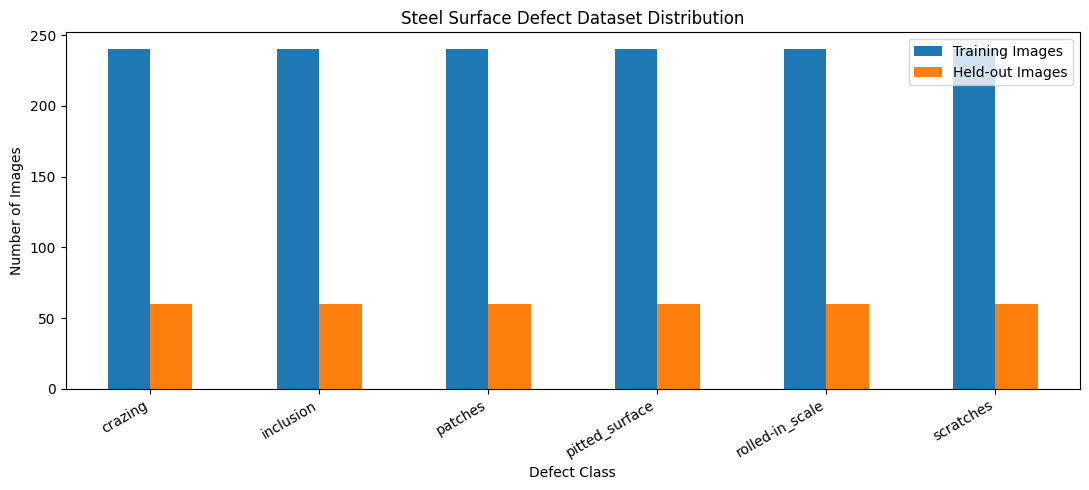

In [ ]:

class_names = sorted(train_counts.keys())

distribution = pd.DataFrame({
    "Defect Class": class_names,
    "Training Images": [train_counts[c] for c in class_names],
    "Held-out Images": [test_counts.get(c, 0) for c in class_names]
})

display(distribution)

distribution.set_index("Defect Class").plot(
    kind="bar", figsize=(11, 5)
)
plt.title("Steel Surface Defect Dataset Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


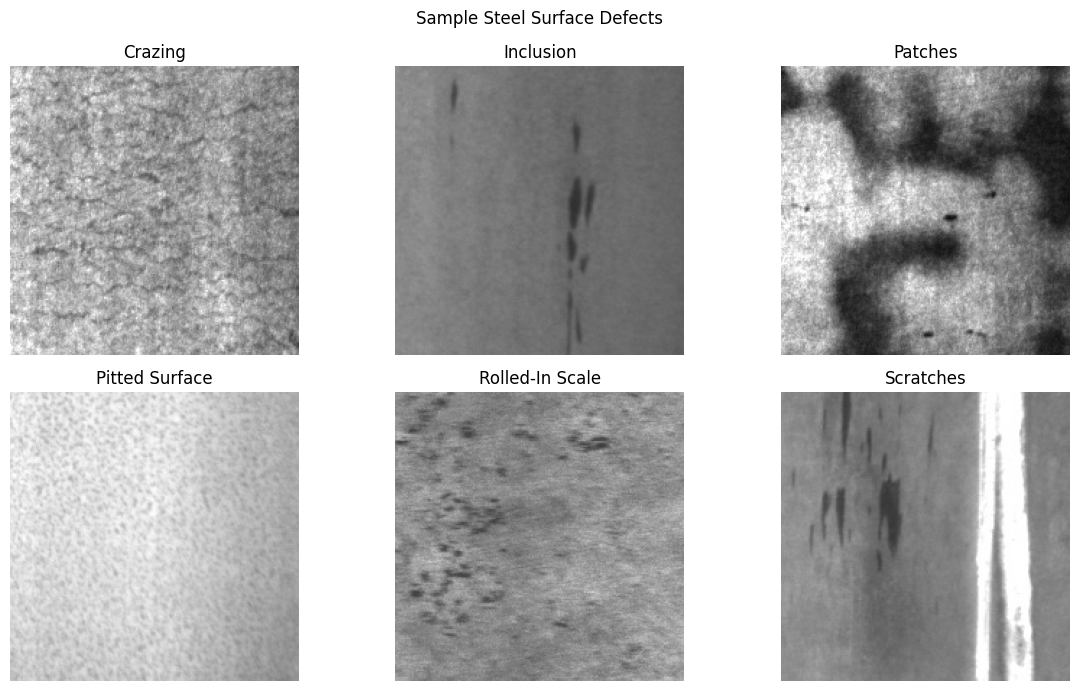

In [ ]:

from PIL import Image

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, name in zip(axes.flat, class_names):
    folder = Path(train_dir) / name
    files = [
        f for f in folder.iterdir()
        if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"}
    ]
    if files:
        img = Image.open(files[0])
        ax.imshow(img, cmap="gray")
        ax.set_title(name.replace("_", " ").title())
    ax.axis("off")

plt.suptitle("Sample Steel Surface Defects")
plt.tight_layout()
plt.show()


In [ ]:

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Create training and validation datasets from the training folder
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int"
)

# Keep the provided validation folder untouched until final evaluation
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    color_mode="grayscale",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
NUM_CLASSES = len(class_names)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

# Normalize pixel values and improve input pipeline efficiency
AUTOTUNE = tf.data.AUTOTUNE

def normalize_images(images, labels):
    images = tf.cast(images, tf.float32) / 255.0
    return images, labels

train_ds = train_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

val_ds = val_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)

test_ds = test_ds.map(
    normalize_images, num_parallel_calls=AUTOTUNE
).prefetch(AUTOTUNE)


Found 1440 files belonging to 6 classes.
Using 1152 files for training.
Found 1440 files belonging to 6 classes.
Using 288 files for validation.
Found 360 files belonging to 6 classes.
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6


Batch shape: (32, 128, 128, 1)
Minimum pixel value: 5.7444853155175224e-05
Maximum pixel value: 1.0


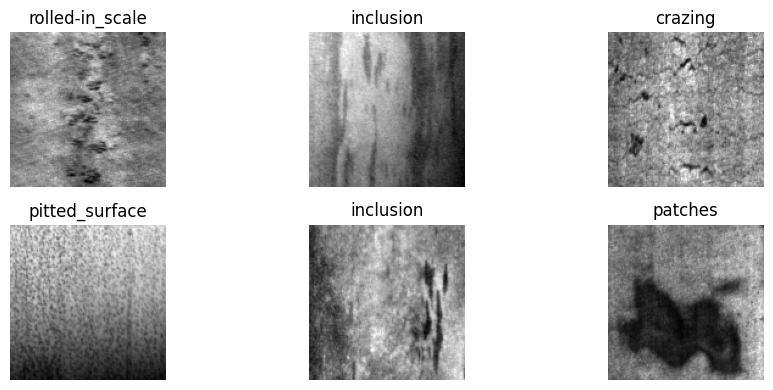

In [ ]:

images, labels = next(iter(train_ds))

print("Batch shape:", images.shape)
print("Minimum pixel value:", float(tf.reduce_min(images)))
print("Maximum pixel value:", float(tf.reduce_max(images)))

plt.figure(figsize=(10, 4))

for i in range(min(6, len(images))):
    plt.subplot(2, 3, i + 1)
    plt.imshow(tf.squeeze(images[i]), cmap="gray")
    plt.title(class_names[int(labels[i])])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from tensorflow.keras import layers, models, regularizers

# Data augmentation is applied only to training images
augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.10)
], name="data_augmentation")

def build_cnn():
    inputs = layers.Input(shape=(128, 128, 1))

    x = augmentation(inputs)

    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(
        128, 3, padding="same", activation="relu",
        name="last_conv"
    )(x)
    x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.35)(x)
    x = layers.Dense(
        64, activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    )(x)
    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(
        NUM_CLASSES, activation="softmax"
    )(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

cnn_model = build_cnn()
cnn_model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,318 (395.77 KB)

 Trainable params: 101,318 (395.77 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_cnn.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=callbacks
)

cnn_model.save("/content/steel_cnn_model.keras")
print("CNN training complete.")


Epoch 1/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1640 - loss: 1.8649
Epoch 1: val_loss improved from None to 1.82684, saving model to /content/best_cnn.keras

Epoch 1: finished saving model to /content/best_cnn.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.1667 - loss: 1.8496 - val_accuracy: 0.1806 - val_loss: 1.8268 - learning_rate: 0.0010
Epoch 2/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.2004 - loss: 1.7904
Epoch 2: val_loss improved from 1.82684 to 1.68187, saving model to /content/best_cnn.keras

Epoch 2: finished saving model to /content/best_cnn.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 47s 1s/step - accuracy: 0.2378 - loss: 1.7554 - val_accuracy: 0.2708 - val_loss: 1.6819 - learning_rate: 0.0010
Epoch 3/30
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.3250 - loss: 1.6446
Epoch 3: val_loss improved from 1.68187 to 1.63799, saving model to /content/best_cnn.keras

Epoch 3: finished saving model to /content/best_cnn.keras
36/36 ━━━━━━━━━━━━━━━━━

,accuracy,loss,val_accuracy,val_loss,learning_rate
19,0.793403,0.668916,0.649306,0.955171,0.00100
20,0.816840,0.627405,0.652778,0.949301,0.00100
21,0.839410,0.549556,0.579861,1.288947,0.00050
22,0.839410,0.555522,0.555556,1.490578,0.00050
23,0.845486,0.536942,0.597222,1.270025,0.00025


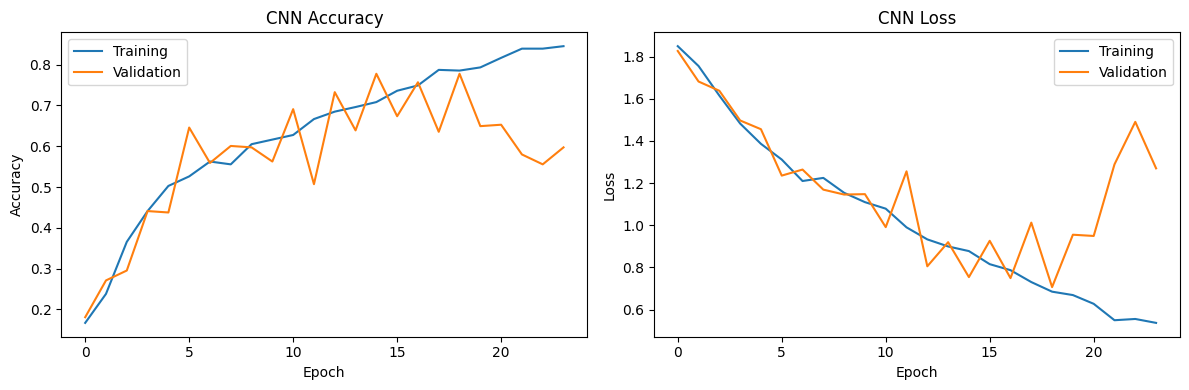

In [ ]:

history_df = pd.DataFrame(history.history)
display(history_df.tail())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("CNN Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [ ]:

# CELL 11 — Correct RGB dataset pipeline

import tensorflow as tf

SEED = 42
BATCH_SIZE = 32
TRANSFER_SIZE = (160, 160)
AUTOTUNE = tf.data.AUTOTUNE

train_rgb = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    image_size=TRANSFER_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

val_rgb = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    image_size=TRANSFER_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

test_rgb = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=TRANSFER_SIZE,
    color_mode="rgb",
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# Verify that all datasets use the same class order
class_names = train_rgb.class_names
NUM_CLASSES = len(class_names)

assert val_rgb.class_names == class_names
assert test_rgb.class_names == class_names

# IMPORTANT:
# Keep pixel values in the original 0–255 range.
# Preprocessing will happen inside the model exactly once.

train_rgb = train_rgb.prefetch(AUTOTUNE)
val_rgb = val_rgb.prefetch(AUTOTUNE)
test_rgb = test_rgb.prefetch(AUTOTUNE)

print("Classes:", class_names)
print("Number of classes:", NUM_CLASSES)

sample_images, sample_labels = next(iter(train_rgb))

print("Image shape:", sample_images.shape)
print("Pixel minimum:", float(tf.reduce_min(sample_images)))
print("Pixel maximum:", float(tf.reduce_max(sample_images)))


Found 1440 files belonging to 6 classes.
Using 1152 files for training.
Found 1440 files belonging to 6 classes.
Using 288 files for validation.
Found 360 files belonging to 6 classes.
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6
Image shape: (32, 160, 160, 3)
Pixel minimum: 0.046875
Pixel maximum: 255.0


In [ ]:

# CELL 12 — Correct MobileNetV2 model

import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Augmentation is active during training only
rgb_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.10)
], name="rgb_augmentation")

def build_transfer_model():

    base = MobileNetV2(
        input_shape=(160, 160, 3),
        include_top=False,
        weights="imagenet"
    )

    # Freeze the pretrained backbone initially
    base.trainable = False

    inputs = layers.Input(
        shape=(160, 160, 3),
        name="steel_image"
    )

    # Dataset images enter as RGB pixel values in [0, 255]
    x = rgb_augmentation(inputs)

    # Apply MobileNetV2 preprocessing ONCE
    x = layers.Lambda(
        preprocess_input,
        name="mobilenet_preprocessing"
    )(x)

    x = base(x, training=False)

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling2d"
    )(x)

    x = layers.Dropout(0.3, name="classification_dropout")(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="defect_predictions"
    )(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

# Build a fresh model; do not reuse the old trained weights
transfer_model = build_transfer_model()

transfer_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ steel_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rgb_augmentation (Sequential)   │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 160, 160, 3)    │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classification_dropout          │ (None, 1280)           │             0 │
│ (Dropout)                       │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ defect_predictions (Dense)      │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

# CELL 14 — Training callbacks

transfer_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# CELL 15 — Train the corrected model

transfer_history = transfer_model.fit(
    train_rgb,
    validation_data=val_rgb,
    epochs=15,
    callbacks=transfer_callbacks
)

# Save the corrected model
transfer_model.save("/content/steel_defect_model.keras")

print("Corrected MobileNetV2 training completed.")


Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 789ms/step - accuracy: 0.4623 - loss: 1.5085
Epoch 1: val_loss improved from None to 0.34588, saving model to /content/best_mobilenet.keras

Epoch 1: finished saving model to /content/best_mobilenet.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 42s 985ms/step - accuracy: 0.6745 - loss: 0.9552 - val_accuracy: 0.9306 - val_loss: 0.3459 - learning_rate: 0.0010
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 797ms/step - accuracy: 0.9216 - loss: 0.2628
Epoch 2: val_loss improved from 0.34588 to 0.16563, saving model to /content/best_mobilenet.keras

Epoch 2: finished saving model to /content/best_mobilenet.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 40s 973ms/step - accuracy: 0.9427 - loss: 0.2065 - val_accuracy: 0.9618 - val_loss: 0.1656 - learning_rate: 0.0010
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 766ms/step - accuracy: 0.9697 - loss: 0.1383
Epoch 3: val_loss improved from 0.16563 to 0.15626, saving model to /content/best_mobilenet.keras

Epoch 3: finished saving model to /c

In [ ]:

# CELL 14 — Training callbacks

transfer_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

# CELL 15 — Train the corrected model

transfer_history = transfer_model.fit(
    train_rgb,
    validation_data=val_rgb,
    epochs=15,
    callbacks=transfer_callbacks
)

# Save the corrected model
transfer_model.save("/content/steel_defect_model.keras")

print("Corrected MobileNetV2 training completed.")


Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 785ms/step - accuracy: 0.9955 - loss: 0.0261
Epoch 1: val_loss improved from None to 0.07360, saving model to /content/best_mobilenet.keras

Epoch 1: finished saving model to /content/best_mobilenet.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 35s 949ms/step - accuracy: 0.9948 - loss: 0.0284 - val_accuracy: 0.9757 - val_loss: 0.0736 - learning_rate: 5.0000e-04
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 801ms/step - accuracy: 0.9930 - loss: 0.0314
Epoch 2: val_loss improved from 0.07360 to 0.06697, saving model to /content/best_mobilenet.keras

Epoch 2: finished saving model to /content/best_mobilenet.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.9939 - loss: 0.0295 - val_accuracy: 0.9757 - val_loss: 0.0670 - learning_rate: 5.0000e-04
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 766ms/step - accuracy: 0.9908 - loss: 0.0310
Epoch 3: val_loss improved from 0.06697 to 0.06234, saving model to /content/best_mobilenet.keras

Epoch 3: finished saving model 

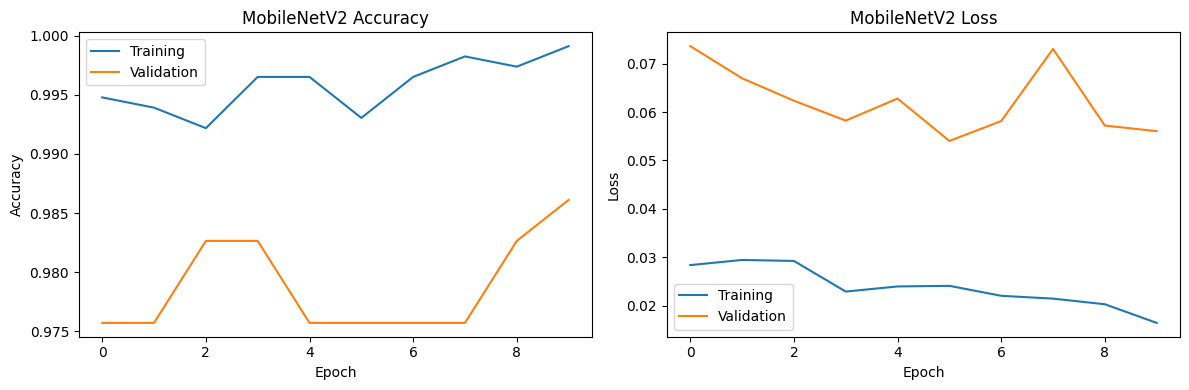

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(transfer_history.history["accuracy"], label="Training")
plt.plot(transfer_history.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(transfer_history.history["loss"], label="Training")
plt.plot(transfer_history.history["val_loss"], label="Validation")
plt.title("MobileNetV2 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

# Register the preprocessing function for this load operation
transfer_model = tf.keras.models.load_model(
    "/content/best_mobilenet.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("Model loaded successfully!")
print("Input shape:", transfer_model.input_shape)
print("Output shape:", transfer_model.output_shape)


Model loaded successfully!
Input shape: (None, 160, 160, 3)
Output shape: (None, 6)


12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 768ms/step
Test accuracy: 95.00%

Classification report:
                 precision    recall  f1-score   support

        crazing       0.87      1.00      0.93        60
      inclusion       1.00      0.88      0.94        60
        patches       0.95      1.00      0.98        60
 pitted_surface       0.93      0.83      0.88        60
rolled-in_scale       0.97      1.00      0.98        60
      scratches       1.00      0.98      0.99        60

       accuracy                           0.95       360
      macro avg       0.95      0.95      0.95       360
   weighted avg       0.95      0.95      0.95       360



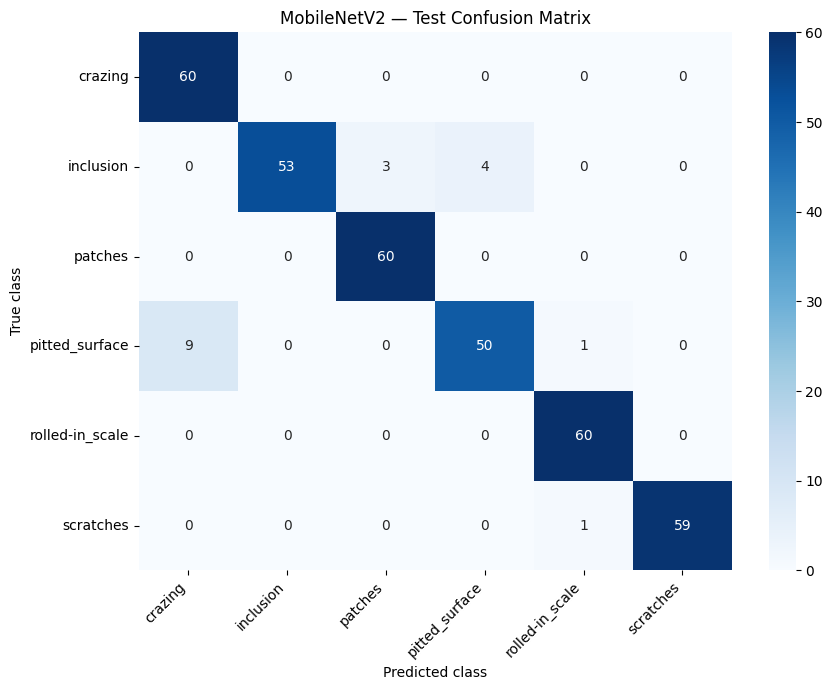

In [ ]:

import numpy as np
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get true labels
y_true = np.concatenate([
    labels.numpy() for _, labels in test_rgb
])

# Predict using the loaded model
y_prob = transfer_model.predict(test_rgb, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Metrics
test_accuracy = accuracy_score(y_true, y_pred)
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.title("MobileNetV2 — Test Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 7 — Inspect the model's mistakes

import pandas as pd
import numpy as np

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

print("Confusion matrix:")
display(cm_df)

print("\nMost common misclassifications:")

errors = []
for true_idx, true_class in enumerate(class_names):
    for pred_idx, pred_class in enumerate(class_names):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            errors.append({
                "Actual class": true_class,
                "Predicted as": pred_class,
                "Incorrect images": int(cm[true_idx, pred_idx])
            })

errors_df = pd.DataFrame(errors)

if not errors_df.empty:
    display(
        errors_df.sort_values(
            "Incorrect images",
            ascending=False
        ).head(15)
    )


Confusion matrix:


,crazing,inclusion,patches,pitted_surface,rolled-in_scale,scratches
crazing,60,0,0,0,0,0
inclusion,0,53,3,4,0,0
patches,0,0,60,0,0,0
pitted_surface,9,0,0,50,1,0
rolled-in_scale,0,0,0,0,60,0
scratches,0,0,0,0,1,59



Most common misclassifications:


,Actual class,Predicted as,Incorrect images
2,pitted_surface,crazing,9
1,inclusion,pitted_surface,4
0,inclusion,patches,3
3,pitted_surface,rolled-in_scale,1
4,scratches,rolled-in_scale,1


In [ ]:

# STEP 8 — Fine-tune MobileNetV2

import tensorflow as tf
from tensorflow.keras import layers

# Start with the current trained model
# Do NOT reload the old checkpoint here.
model_ft = transfer_model

# Find the pretrained MobileNetV2 backbone
backbone = next(
    layer for layer in model_ft.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

print("Backbone:", backbone.name)
print("Total backbone layers:", len(backbone.layers))

# Unfreeze the backbone, then freeze all but its final 30 layers
backbone.trainable = True

for layer in backbone.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

print(
    "Trainable backbone layers:",
    sum(layer.trainable for layer in backbone.layers)
)

# Use a much smaller learning rate
model_ft.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

fine_tune_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_mobilenet_finetuned.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

fine_tune_history = model_ft.fit(
    train_rgb,
    validation_data=val_rgb,
    epochs=12,
    callbacks=fine_tune_callbacks
)

model_ft.save("/content/steel_defect_model_finetuned.keras")

print("Fine-tuning complete.")


Backbone: mobilenetv2_1.00_160
Total backbone layers: 154
Trainable backbone layers: 19
Epoch 1/12
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9984 - loss: 0.0192
Epoch 1: val_loss improved from None to 0.02032, saving model to /content/best_mobilenet_finetuned.keras

Epoch 1: finished saving model to /content/best_mobilenet_finetuned.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.9974 - loss: 0.0193 - val_accuracy: 0.9931 - val_loss: 0.0203 - learning_rate: 1.0000e-05
Epoch 2/12
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9939 - loss: 0.0249
Epoch 2: val_loss did not improve from 0.02032
36/36 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.9948 - loss: 0.0241 - val_accuracy: 0.9896 - val_loss: 0.0401 - learning_rate: 1.0000e-05
Epoch 3/12
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 958ms/step - accuracy: 0.9980 - loss: 0.0132
Epoch 3: val_loss did not improve from 0.02032

Epoch 3: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
36/36 ━━━━━━━━━━━━━━━━━

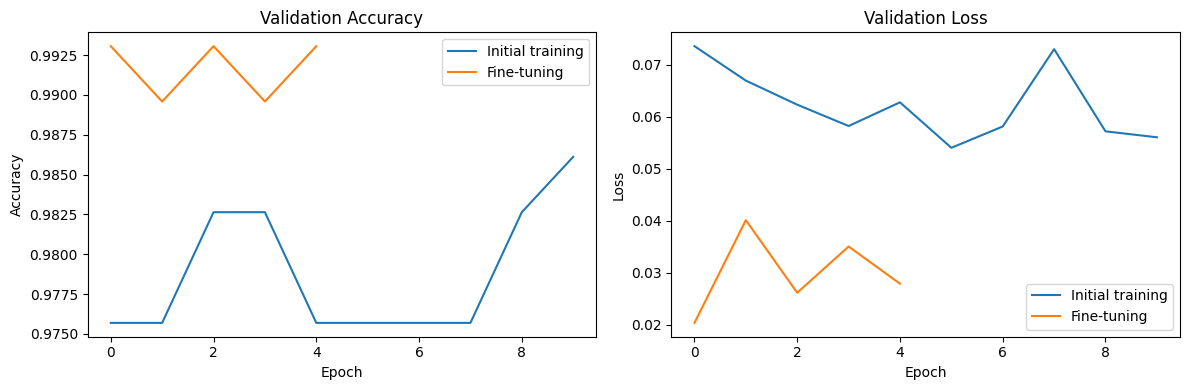

In [ ]:

# STEP 9 — Compare validation accuracy and loss

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(
    transfer_history.history["val_accuracy"],
    label="Initial training"
)
plt.plot(
    fine_tune_history.history["val_accuracy"],
    label="Fine-tuning"
)
plt.title("Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(
    transfer_history.history["val_loss"],
    label="Initial training"
)
plt.plot(
    fine_tune_history.history["val_loss"],
    label="Fine-tuning"
)
plt.title("Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 740ms/step
Fine-tuned test accuracy: 92.50%
                 precision    recall  f1-score   support

        crazing       0.80      1.00      0.89        60
      inclusion       1.00      0.83      0.91        60
        patches       0.94      1.00      0.97        60
 pitted_surface       0.92      0.75      0.83        60
rolled-in_scale       0.97      0.98      0.98        60
      scratches       0.97      0.98      0.98        60

       accuracy                           0.93       360
      macro avg       0.93      0.92      0.92       360
   weighted avg       0.93      0.93      0.92       360



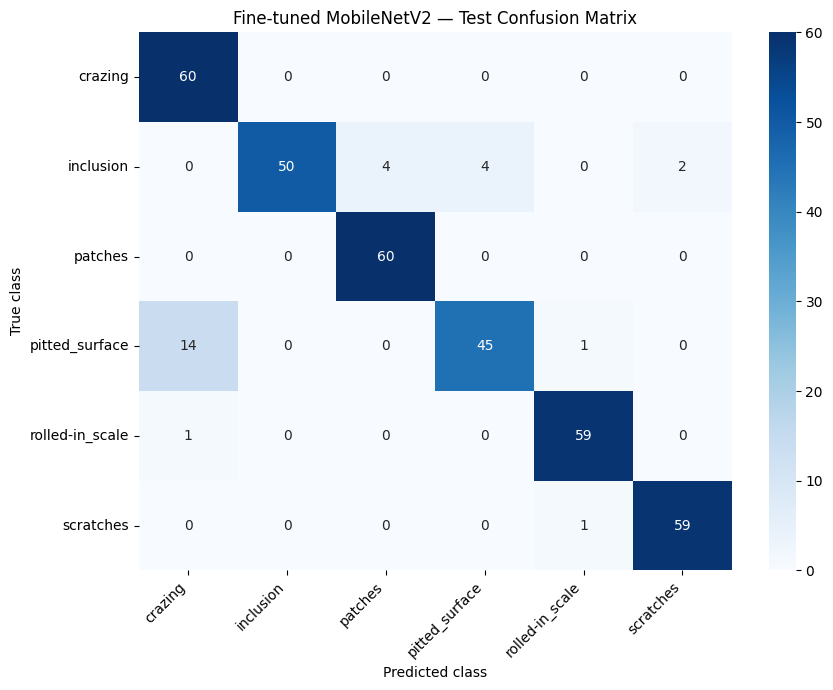

In [ ]:

# STEP 10 — Final test evaluation of the fine-tuned model

import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Use the best weights restored by EarlyStopping
y_true_ft = np.concatenate([
    labels.numpy() for _, labels in test_rgb
])

y_prob_ft = model_ft.predict(test_rgb, verbose=1)
y_pred_ft = np.argmax(y_prob_ft, axis=1)

print(
    f"Fine-tuned test accuracy: "
    f"{accuracy_score(y_true_ft, y_pred_ft) * 100:.2f}%"
)

print(classification_report(
    y_true_ft,
    y_pred_ft,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    zero_division=0
))

cm_ft = confusion_matrix(
    y_true_ft,
    y_pred_ft,
    labels=np.arange(len(class_names))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm_ft,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Fine-tuned MobileNetV2 — Test Confusion Matrix")
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras import layers, models
import tensorflow as tf

# Separate augmentation for RGB transfer-learning images
rgb_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomZoom(0.10)
], name="rgb_augmentation")


def build_transfer_model():
    # Load pretrained MobileNetV2
    base = MobileNetV2(
        input_shape=(160, 160, 3),
        include_top=False,
        weights="imagenet"
    )

    # Freeze pretrained layers initially
    base.trainable = False

    # RGB input: 160 x 160 x 3
    inputs = layers.Input(shape=(160, 160, 3))

    # Augment images without changing their channel count
    x = rgb_augmentation(inputs)

    # MobileNetV2 requires its own input preprocessing
    x = layers.Lambda(
        preprocess_input,
        name="mobilenet_preprocessing"
    )(x * 255.0)

    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="defect_predictions"
    )(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


transfer_model = build_transfer_model()
transfer_model.summary()


Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rgb_augmentation (Sequential)   │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ multiply (Multiply)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 160, 160, 3)    │             0 │
│ (Lambda)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ defect_predictions (Dense)      │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

print("Model input shape:", transfer_model.input_shape)
print("Number of classes:", NUM_CLASSES)

images, labels = next(iter(train_rgb))

print("Dataset image shape:", images.shape)


Model input shape: (None, 160, 160, 3)
Number of classes: 6
Dataset image shape: (32, 160, 160, 3)


In [ ]:

import tensorflow as tf

transfer_callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

print("Transfer-learning callbacks created successfully!")


Transfer-learning callbacks created successfully!


In [ ]:

transfer_history = transfer_model.fit(
    train_rgb,
    validation_data=val_rgb,
    epochs=15,
    callbacks=transfer_callbacks
)

transfer_model.save("/content/steel_mobilenet_model.keras")

print("MobileNetV2 training completed successfully!")


Epoch 1/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 811ms/step - accuracy: 0.3668 - loss: 1.7015
Epoch 1: val_loss improved from None to 2.20991, saving model to /content/best_mobilenet.keras

Epoch 1: finished saving model to /content/best_mobilenet.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 48s 1s/step - accuracy: 0.5191 - loss: 1.2768 - val_accuracy: 0.1875 - val_loss: 2.2099 - learning_rate: 0.0010
Epoch 2/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 824ms/step - accuracy: 0.7658 - loss: 0.6352
Epoch 2: val_loss improved from 2.20991 to 1.50852, saving model to /content/best_mobilenet.keras

Epoch 2: finished saving model to /content/best_mobilenet.keras
36/36 ━━━━━━━━━━━━━━━━━━━━ 36s 988ms/step - accuracy: 0.7856 - loss: 0.6041 - val_accuracy: 0.6215 - val_loss: 1.5085 - learning_rate: 0.0010
Epoch 3/15
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 843ms/step - accuracy: 0.7760 - loss: 0.5612
Epoch 3: val_loss did not improve from 1.50852
36/36 ━━━━━━━━━━━━━━━━━━━━ 42s 1s/step - accuracy: 0.8142 - loss: 0.4957 - val_accuracy: 0.

In [ ]:

print("CNN model available:", "cnn_model" in globals())
print("MobileNetV2 available:", "transfer_model" in globals())
print("Training history available:", "transfer_history" in globals())

if "transfer_history" in globals():
    print("Completed epochs:", len(transfer_history.history["loss"]))


CNN model available: True
MobileNetV2 available: True
Training history available: True
Completed epochs: 9


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Predict the classes of held-out RGB images
y_true_rgb = np.concatenate([
    labels.numpy() for _, labels in test_rgb
])

y_prob_rgb = transfer_model.predict(test_rgb, verbose=1)
y_pred_rgb = np.argmax(y_prob_rgb, axis=1)

print("MobileNetV2 Accuracy:",
      round(accuracy_score(y_true_rgb, y_pred_rgb), 4))

print("Macro Precision:",
      round(precision_score(
          y_true_rgb, y_pred_rgb,
          average="macro", zero_division=0
      ), 4))

print("Macro Recall:",
      round(recall_score(
          y_true_rgb, y_pred_rgb,
          average="macro", zero_division=0
      ), 4))

print("Macro F1-score:",
      round(f1_score(
          y_true_rgb, y_pred_rgb,
          average="macro", zero_division=0
      ), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_true_rgb,
    y_pred_rgb,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))


12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 682ms/step
MobileNetV2 Accuracy: 0.5806
Macro Precision: 0.6257
Macro Recall: 0.5806
Macro F1-score: 0.5084

Classification Report:

                 precision    recall  f1-score   support

        crazing       0.76      0.93      0.84        60
      inclusion       1.00      0.03      0.06        60
        patches       0.92      1.00      0.96        60
 pitted_surface       0.33      0.68      0.44        60
rolled-in_scale       0.62      0.80      0.70        60
      scratches       0.13      0.03      0.05        60

       accuracy                           0.58       360
      macro avg       0.63      0.58      0.51       360
   weighted avg       0.63      0.58      0.51       360



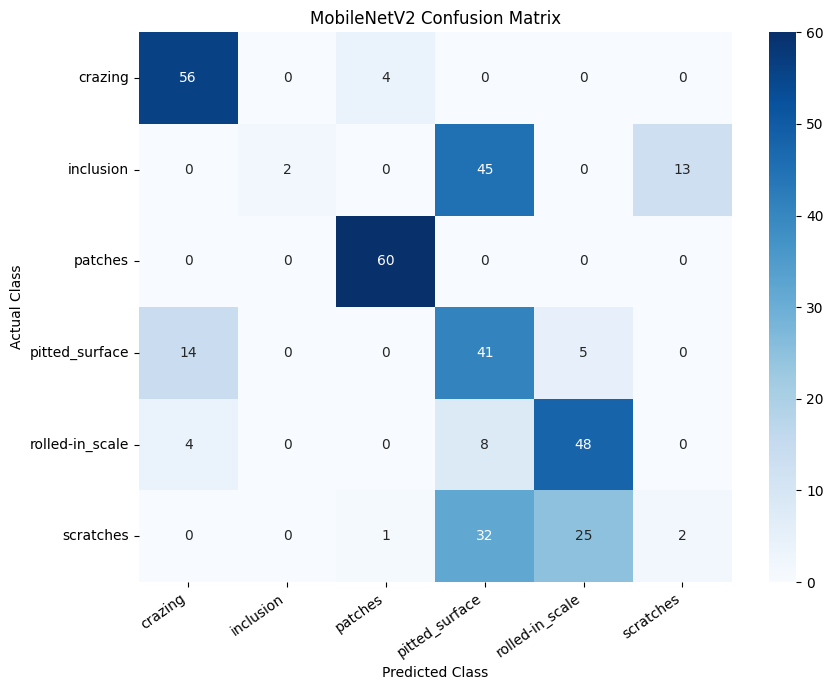

In [ ]:

cm_rgb = confusion_matrix(
    y_true_rgb,
    y_pred_rgb,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_rgb,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def evaluate_model(model, dataset, model_name):

    # Get actual labels
    actual = np.concatenate([
        labels.numpy() for _, labels in dataset
    ])

    # Generate predictions
    probabilities = model.predict(dataset, verbose=0)
    predicted = np.argmax(probabilities, axis=1)

    # Calculate performance metrics
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(actual, predicted),
        "Macro Precision": precision_score(
            actual, predicted,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            actual, predicted,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            actual, predicted,
            average="macro", zero_division=0
        )
    }

print("evaluate_model() defined successfully!")


evaluate_model() defined successfully!


In [ ]:

import tensorflow as tf

print("GPU:", tf.config.list_physical_devices("GPU"))
print("CNN available:", "cnn_model" in globals())
print("MobileNetV2 available:", "transfer_model" in globals())


GPU: []
CNN available: True
MobileNetV2 available: True


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

def evaluate_model_fast(model, dataset, model_name, max_images=300):
    actual_batches = []
    predicted_batches = []
    total = 0

    for images, labels in dataset:
        # Limit the number of evaluated images
        remaining = max_images - total
        if remaining <= 0:
            break

        images = images[:remaining]
        labels = labels[:remaining]

        # Direct inference on each batch
        probs = model(images, training=False).numpy()
        preds = np.argmax(probs, axis=1)

        actual_batches.extend(labels.numpy().tolist())
        predicted_batches.extend(preds.tolist())
        total += len(labels)

        print(f"{model_name}: evaluated {total} images")

    actual = np.array(actual_batches)
    predicted = np.array(predicted_batches)

    return {
        "Model": model_name,
        "Images Evaluated": total,
        "Accuracy": accuracy_score(actual, predicted),
        "Macro Precision": precision_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            actual, predicted, average="macro", zero_division=0
        )
    }

print("Fast evaluation function ready!")


Fast evaluation function ready!


In [ ]:

cnn_result = evaluate_model_fast(
    cnn_model, test_ds, "Custom CNN", max_images=300
)

mobilenet_result = evaluate_model_fast(
    transfer_model, test_rgb, "MobileNetV2", max_images=300
)

comparison = pd.DataFrame([
    cnn_result,
    mobilenet_result
])

display(comparison.round(4))

comparison.to_csv(
    "/content/model_comparison.csv",
    index=False
)


Custom CNN: evaluated 32 images
Custom CNN: evaluated 64 images
Custom CNN: evaluated 96 images
Custom CNN: evaluated 128 images
Custom CNN: evaluated 160 images
Custom CNN: evaluated 192 images
Custom CNN: evaluated 224 images
Custom CNN: evaluated 256 images
Custom CNN: evaluated 288 images
Custom CNN: evaluated 300 images
MobileNetV2: evaluated 32 images
MobileNetV2: evaluated 64 images
MobileNetV2: evaluated 96 images
MobileNetV2: evaluated 128 images
MobileNetV2: evaluated 160 images
MobileNetV2: evaluated 192 images
MobileNetV2: evaluated 224 images
MobileNetV2: evaluated 256 images
MobileNetV2: evaluated 288 images
MobileNetV2: evaluated 300 images


,Model,Images Evaluated,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Custom CNN,300,0.6367,0.5619,0.5306,0.5165
1,MobileNetV2,300,0.6900,0.6727,0.5750,0.5417


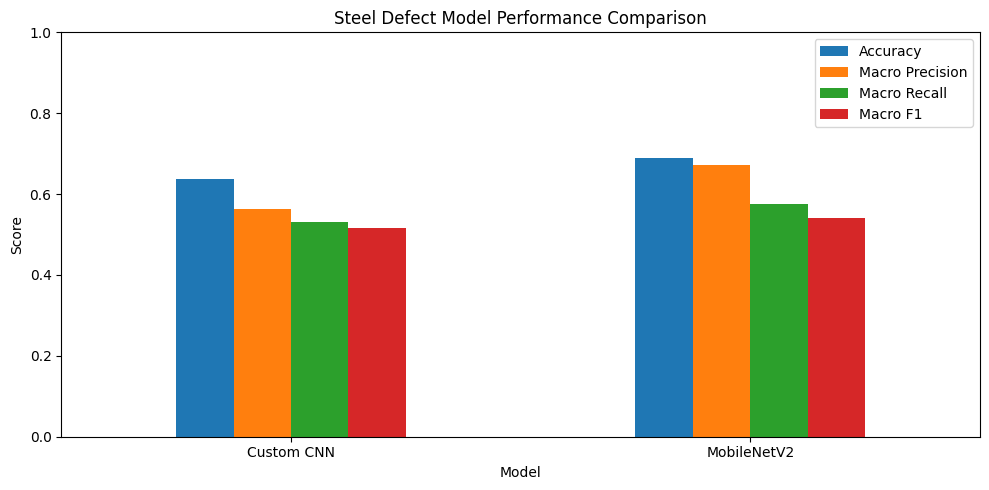

In [ ]:

metrics = [
    "Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

import matplotlib.pyplot as plt

plt.title("Steel Defect Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 460ms/step
                 precision    recall  f1-score   support

        crazing       0.76      0.93      0.84        60
      inclusion       1.00      0.03      0.06        60
        patches       0.92      1.00      0.96        60
 pitted_surface       0.33      0.68      0.44        60
rolled-in_scale       0.62      0.80      0.70        60
      scratches       0.13      0.03      0.05        60

       accuracy                           0.58       360
      macro avg       0.63      0.58      0.51       360
   weighted avg       0.63      0.58      0.51       360



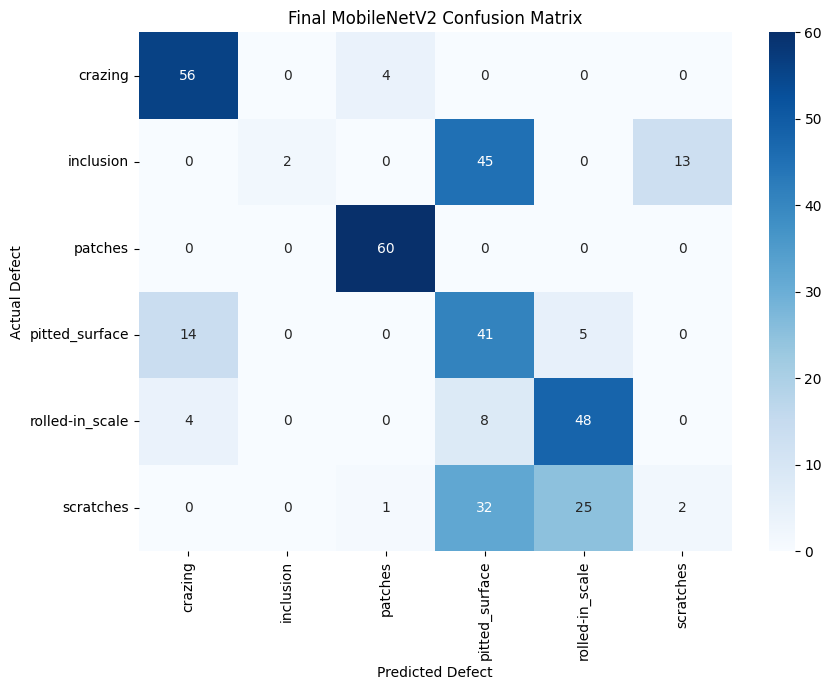

In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Predict all held-out images
y_true = np.concatenate([
    labels.numpy() for _, labels in test_rgb
])

y_prob = transfer_model.predict(test_rgb, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("Final MobileNetV2 Confusion Matrix")
plt.xlabel("Predicted Defect")
plt.ylabel("Actual Defect")
plt.tight_layout()
plt.savefig("/content/final_confusion_matrix.png", dpi=200)
plt.show()


In [ ]:
sample_images, sample_labels = next(iter(test_rgb))
sample = sample_images[0:1]

print("Minimum pixel value:", float(tf.reduce_min(sample)))
print("Maximum pixel value:", float(tf.reduce_max(sample)))
print("Image shape:", sample.shape)

Minimum pixel value: 70.609375
Maximum pixel value: 255.0
Image shape: (1, 160, 160, 3)


In [ ]:

def make_gradcam(model, image_batch):

    base = model.get_layer("mobilenetv2_1.00_160")

    # Use the actual layer names from your model
    gap = model.get_layer("global_average_pooling2d_1")
    dropout = model.get_layer("dropout_2")
    classifier = model.get_layer("defect_predictions")

    with tf.GradientTape() as tape:

        augmented = model.get_layer("rgb_augmentation")(
            image_batch, training=False
        )

        preprocessed = model.get_layer("mobilenet_preprocessing")(
            augmented * 255.0
        )

        # Extract final convolutional feature maps
        conv_outputs = base(preprocessed, training=False)

        # Classification head
        pooled = gap(conv_outputs)
        dropped = dropout(pooled, training=False)
        predictions = classifier(dropped)

        class_id = tf.argmax(predictions[0])
        score = predictions[:, class_id]

    grads = tape.gradient(score, conv_outputs)

    if grads is None:
        raise ValueError("Gradients are missing. Check model connections.")

    weights = tf.reduce_mean(grads, axis=(1, 2))

    heatmap = tf.reduce_sum(
        conv_outputs[0] * weights[0][tf.newaxis, tf.newaxis, :],
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)

    return (
        heatmap.numpy(),
        int(class_id.numpy()),
        float(predictions[0, class_id].numpy())
    )


In [ ]:
sample_images, sample_labels = next(iter(test_rgb))
sample = sample_images[0:1]

heatmap, pred_id, confidence = make_gradcam(
    transfer_model, sample
)

print("Predicted class:", class_names[pred_id])
print("Confidence:", f"{confidence:.2%}")
print("Heatmap shape:", heatmap.shape)

Predicted class: crazing
Confidence: 63.89%
Heatmap shape: (5, 5)


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
!pip install opencv-python-headless

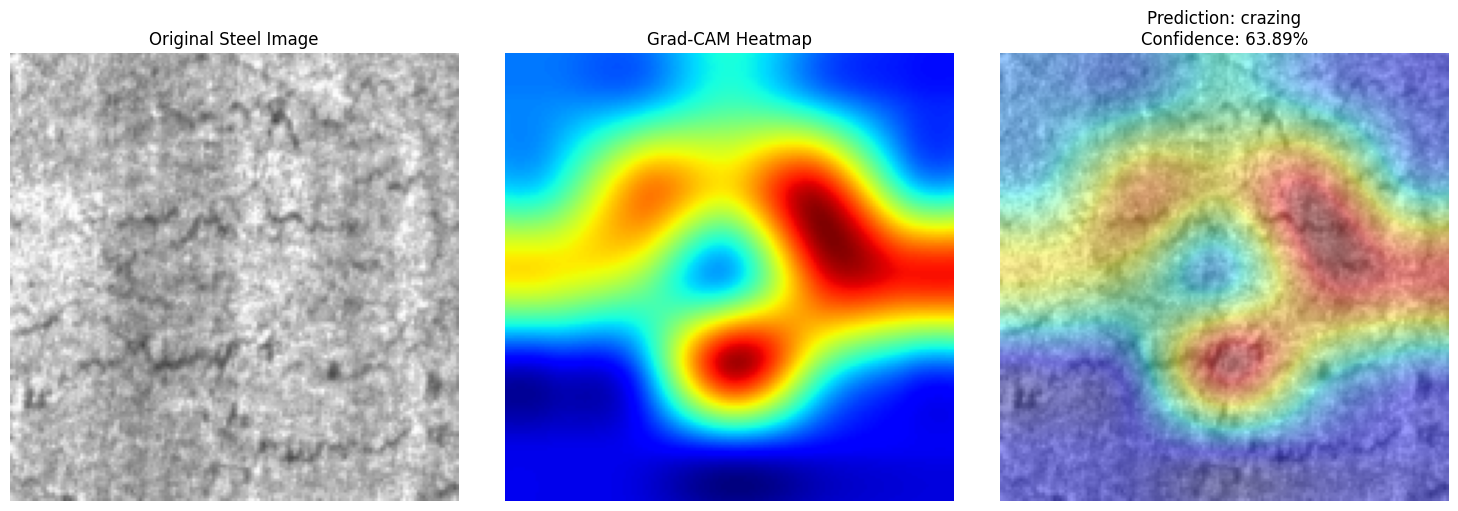

Grad-CAM visualization saved successfully!


In [ ]:
# Convert the sample image for display.
# This assumes test_rgb contains raw RGB pixel values (0–255).
display_img = np.clip(
    sample[0].numpy(), 0, 255
).astype(np.uint8)

heatmap_resized = cv2.resize(
    heatmap,
    (display_img.shape[1], display_img.shape[0]),
    interpolation=cv2.INTER_CUBIC
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(display_img)
plt.title("Original Steel Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(display_img)
plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
plt.title(
    f"Prediction: {class_names[pred_id]}\n"
    f"Confidence: {confidence:.2%}"
)
plt.axis("off")

plt.tight_layout()
plt.savefig("/content/gradcam_result.png", dpi=200)
plt.show()

print("Grad-CAM visualization saved successfully!")

In [ ]:
transfer_model.save("/content/steel_defect_model.keras")

print("Transfer-learning model saved successfully!")

Transfer-learning model saved successfully!


In [ ]:
cnn_model.save("/content/steel_cnn_model.keras")

print("Baseline CNN saved successfully!")

Baseline CNN saved successfully!


In [ ]:
converter = tf.lite.TFLiteConverter.from_keras_model(
    transfer_model
)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

with open("/content/steel_defect_model.tflite", "wb") as f:
    f.write(tflite_model)

print("TensorFlow Lite model created successfully!")
print(
    "Model size:",
    round(len(tflite_model) / (1024 * 1024), 2),
    "MB"
)

Saved artifact at '/tmp/tmp36p_ddep'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='keras_tensor_673')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  132053075504656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053075508880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053075508688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053075509072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053075504464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053075508304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053069325392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053069325584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053075508496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053075504272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1320530693

In [ ]:
from google.colab import files

files.download("/content/steel_defect_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/gradcam_result.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/steel_defect_model.tflite")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

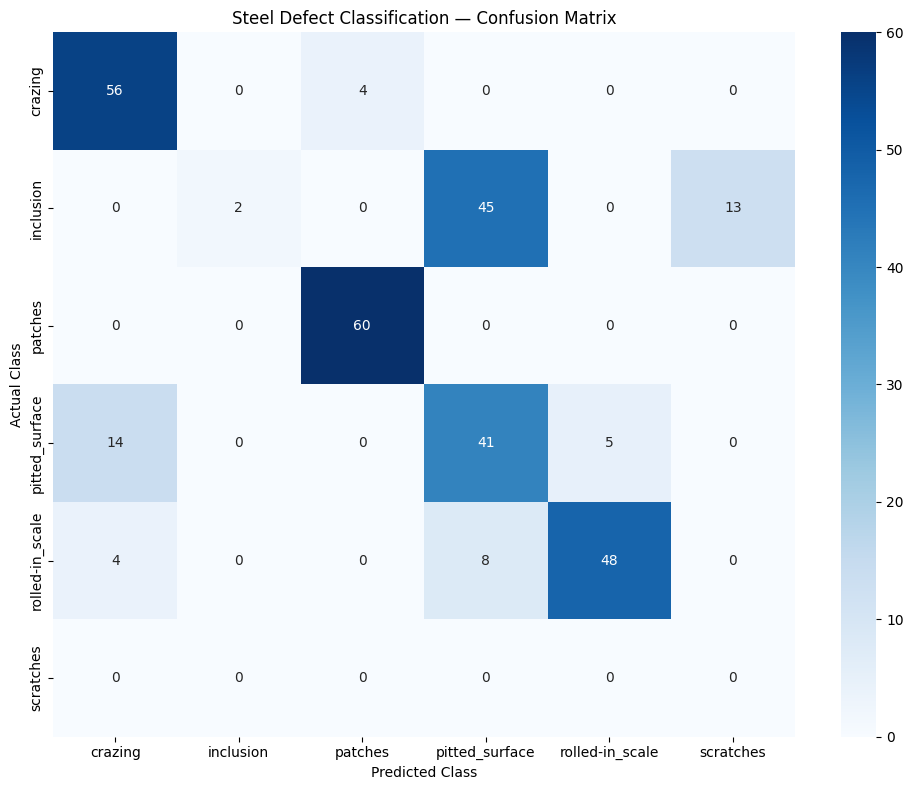

                 precision    recall  f1-score   support

        crazing       0.76      0.93      0.84        60
      inclusion       1.00      0.03      0.06        60
        patches       0.94      1.00      0.97        60
 pitted_surface       0.44      0.68      0.53        60
rolled-in_scale       0.91      0.80      0.85        60
      scratches       0.00      0.00      0.00         0

       accuracy                           0.69       300
      macro avg       0.67      0.58      0.54       300
   weighted avg       0.81      0.69      0.65       300



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

y_true = []
y_pred = []

# Evaluate up to 300 test images to keep evaluation quick
for images, labels in test_rgb:
    predictions = transfer_model.predict(images, verbose=0)

    y_true.extend(labels.numpy().argmax(axis=1)
                  if len(labels.shape) > 1
                  else labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

    if len(y_true) >= 300:
        y_true = y_true[:300]
        y_pred = y_pred[:300]
        break

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Steel Defect Classification — Confusion Matrix")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=200)
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

In [ ]:
transfer_model.save("/content/steel_defect_model.keras")

print("Saved model and visualizations:")
print("/content/steel_defect_model.keras")
print("/content/gradcam_result.png")
print("/content/confusion_matrix.png")

Saved model and visualizations:
/content/steel_defect_model.keras
/content/gradcam_result.png
/content/confusion_matrix.png


In [ ]:
%%writefile /content/app.py
import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.set_page_config(
    page_title="Steel Surface Inspection",
    page_icon="🏭",
    layout="centered"
)

st.title("Steel Surface Defect Inspection")
st.write(
    "Upload a steel-surface image to classify its defect category."
)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "/content/steel_defect_model.keras"
    )

model = load_model()

# Keep the same class order used when training the model.
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

uploaded_file = st.file_uploader(
    "Upload a steel image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded Image", width=400)

    if st.button("Inspect Surface"):
        resized = image.resize((160, 160))
        array = np.array(resized, dtype=np.float32)
        batch = np.expand_dims(array, axis=0)

        probabilities = model.predict(batch, verbose=0)[0]
        predicted_id = int(np.argmax(probabilities))

        st.subheader("Prediction")
        st.write(f"**Defect class:** {class_names[predicted_id]}")
        st.metric(
            "Model confidence",
            f"{probabilities[predicted_id]:.2%}"
        )

        st.caption(
            "This is a research prototype using NEU-DET classes. "
            "Validate it on representative industrial data before "
            "using it for real production inspection."
        )

Writing /content/app.py


In [ ]:
print("Class names:", class_names)
print("Number of classes:", len(class_names))

Class names: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6


In [ ]:
import os

train_dir = "/kaggle/input/neu-surface-defect-database/NEU-DET/train/images"

print("Dataset folders:")
print(sorted([
    folder for folder in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, folder))
]))

Dataset folders:
['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [ ]:
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

print("Output classes:", class_names)

Output classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [ ]:
import os

train_dir = "/kaggle/input/neu-surface-defect-database/NEU-DET/train/images"

class_names = sorted([
    folder for folder in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, folder))
])

print("Class names:", class_names)
print("Number of classes:", len(class_names))

Class names: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Number of classes: 6


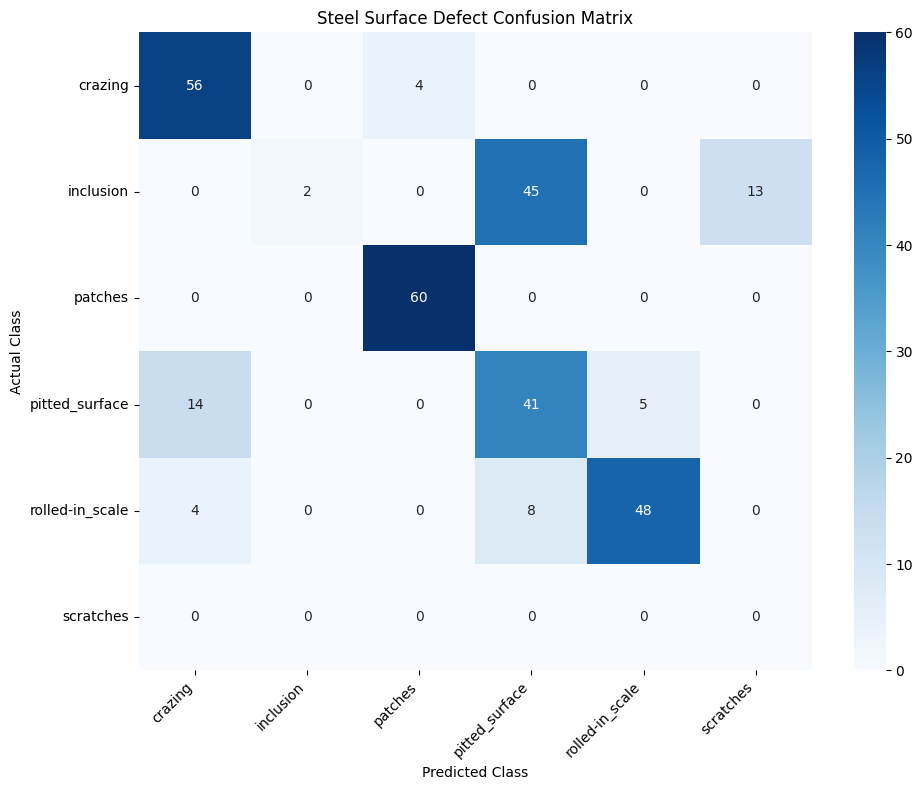

                 precision    recall  f1-score   support

        crazing       0.76      0.93      0.84        60
      inclusion       1.00      0.03      0.06        60
        patches       0.94      1.00      0.97        60
 pitted_surface       0.44      0.68      0.53        60
rolled-in_scale       0.91      0.80      0.85        60
      scratches       0.00      0.00      0.00         0

       accuracy                           0.69       300
      macro avg       0.67      0.58      0.54       300
   weighted avg       0.81      0.69      0.65       300



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

y_true = []
y_pred = []

# Evaluate the test dataset
for images, labels in test_rgb:
    predictions = transfer_model.predict(images, verbose=0)

    # Handle both one-hot and integer labels
    if len(labels.shape) > 1:
        actual = np.argmax(labels.numpy(), axis=1)
    else:
        actual = labels.numpy().astype(int)

    predicted = np.argmax(predictions, axis=1)

    y_true.extend(actual.tolist())
    y_pred.extend(predicted.tolist())

    # Limit evaluation to approximately 300 images
    if len(y_true) >= 300:
        y_true = y_true[:300]
        y_pred = y_pred[:300]
        break

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(len(class_names))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Steel Surface Defect Confusion Matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig("/content/confusion_matrix.png", dpi=200)
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

In [ ]:
from collections import Counter
import numpy as np

actual_counts = Counter()
total_images = 0

for images, labels in test_rgb:
    if len(labels.shape) > 1:
        actual = np.argmax(labels.numpy(), axis=1)
    else:
        actual = labels.numpy().astype(int)

    actual_counts.update(actual.tolist())
    total_images += len(actual)

print("Total test images:", total_images)

for i, name in enumerate(class_names):
    print(f"{name}: {actual_counts.get(i, 0)} images")

Total test images: 360
crazing: 60 images
inclusion: 60 images
patches: 60 images
pitted_surface: 60 images
rolled-in_scale: 60 images
scratches: 60 images


                 precision    recall  f1-score   support

        crazing       0.76      0.93      0.84        60
      inclusion       1.00      0.03      0.06        60
        patches       0.92      1.00      0.96        60
 pitted_surface       0.33      0.68      0.44        60
rolled-in_scale       0.62      0.80      0.70        60
      scratches       0.13      0.03      0.05        60

       accuracy                           0.58       360
      macro avg       0.63      0.58      0.51       360
   weighted avg       0.63      0.58      0.51       360



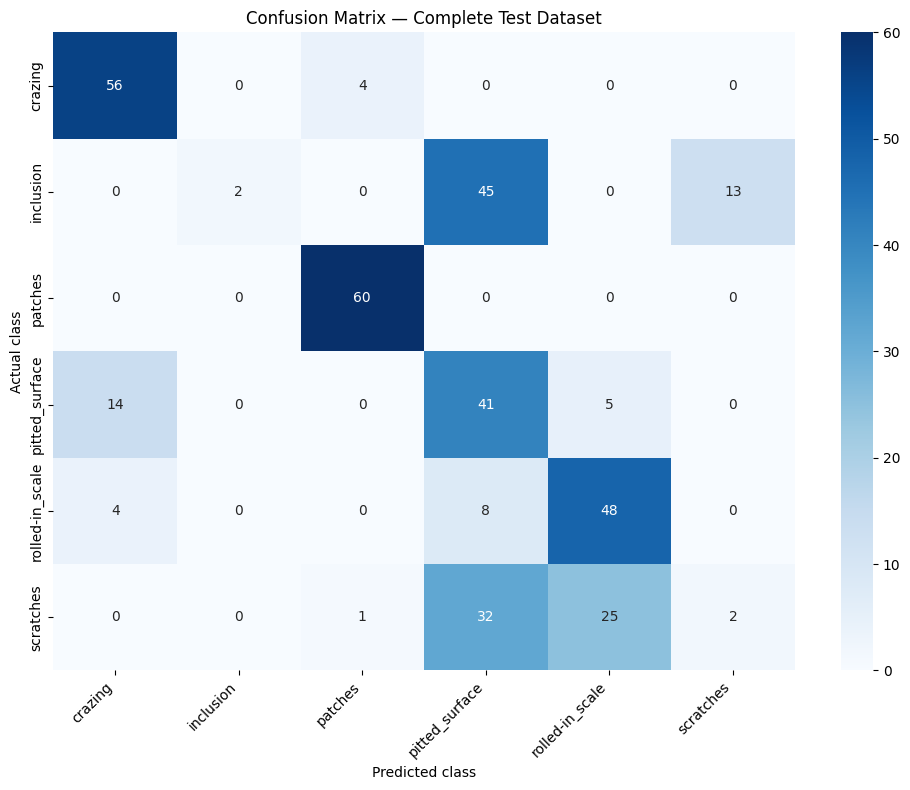

In [ ]:
y_true = []
y_pred = []

for images, labels in test_rgb:
    predictions = transfer_model.predict(images, verbose=0)

    if len(labels.shape) > 1:
        actual = np.argmax(labels.numpy(), axis=1)
    else:
        actual = labels.numpy().astype(int)

    y_true.extend(actual.tolist())
    y_pred.extend(np.argmax(predictions, axis=1).tolist())

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("Confusion Matrix — Complete Test Dataset")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=200)
plt.show()

In [ ]:
transfer_model.save("/content/steel_defect_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [ ]:

%%writefile /content/app.py

import streamlit as st
import tensorflow as tf
import numpy as np
from PIL import Image

st.set_page_config(
    page_title="Steel Defect Inspection",
    page_icon="🏭",
    layout="wide"
)

st.title("🏭 Steel Surface Defect Inspection")
st.write(
    "AI-based surface defect classification using MobileNetV2."
)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "steel_defect_model.keras"
    )

model = load_model()

# Keep this order identical to your training class order.
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

st.sidebar.header("About the project")
st.sidebar.write(
    "This prototype classifies steel surface images "
    "into six NEU-DET defect categories."
)

uploaded_file = st.file_uploader(
    "Upload a steel surface image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")

    left, right = st.columns(2)

    with left:
        st.image(
            image,
            caption="Uploaded steel image",
            use_container_width=True
        )

    with right:
        if st.button("Inspect Surface", type="primary"):
            resized = image.resize((160, 160))
            image_array = np.asarray(
                resized, dtype=np.float32
            )
            batch = np.expand_dims(image_array, axis=0)

            probabilities = model.predict(
                batch, verbose=0
            )[0]

            if len(probabilities) != len(class_names):
                st.error(
                    "The number of model outputs does not match "
                    "the class list. Verify your training class order."
                )
            else:
                predicted_id = int(np.argmax(probabilities))

                st.subheader("Inspection Result")
                st.success(
                    f"Predicted class: {class_names[predicted_id]}"
                )

                st.metric(
                    "Prediction confidence",
                    f"{probabilities[predicted_id]:.2%}"
                )

                st.write("Class probabilities")
                st.bar_chart({
                    "Probability": {
                        class_names[i]: float(probabilities[i])
                        for i in range(len(class_names))
                    }
                })

                st.caption(
                    "Research prototype only. Validate on "
                    "representative industrial images before "
                    "using results for production decisions."
                )


Overwriting /content/app.py


In [ ]:
from google.colab import files

files.download("/content/app.py")
files.download("/content/steel_defect_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
pip install streamlit tensorflow pillow numpy

In [ ]:
!pip -q install streamlit pyngrok

In [ ]:
import os

print("Model exists:", os.path.exists("/content/steel_defect_model.keras"))
print("Dashboard exists:", os.path.exists("/content/app.py"))

Model exists: True
Dashboard exists: True


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 > /content/streamlit.log 2>&1 &

In [ ]:
!cat /content/streamlit.log

In [ ]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏
added 22 packages in 5s
⠋
⠋3 packages are looking for funding
⠋  run `npm fund` for details
⠋

In [ ]:
import os
print(os.path.exists("/content/app.py"))
print(os.listdir("/content")[:30])

True
['.config', 'final_confusion_matrix.png', 'gradcam_result.png', 'best_cnn.keras', 'best_mobilenet.keras', 'best_mobilenet_finetuned.keras', 'app.py', 'steel_mobilenet_model.keras', 'steel_defect_model.keras', 'streamlit.log', 'steel_defect_model.tflite', 'steel_defect_model_finetuned.keras', 'model_comparison.csv', 'steel_project', 'steel_project.zip', 'steel_cnn_model.keras', 'confusion_matrix.png', 'evaluation_results.csv', 'sample_data']


In [ ]:

with open("/content/app.py", "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if "load_model" in line or "def load_model" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 8)
        print(f"\n--- Lines {start + 1} to {end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}", end="")



--- Lines 16 to 26 ---
16: )
17: 
18: @st.cache_resource
19: def load_model():
20:     return tf.keras.models.load_model(
21:         "steel_defect_model.keras"
22:     )
23: 
24: model = load_model()
25: 
26: # Keep this order identical to your training class order.

--- Lines 17 to 27 ---
17: 
18: @st.cache_resource
19: def load_model():
20:     return tf.keras.models.load_model(
21:         "steel_defect_model.keras"
22:     )
23: 
24: model = load_model()
25: 
26: # Keep this order identical to your training class order.
27: class_names = [

--- Lines 21 to 31 ---
21:         "steel_defect_model.keras"
22:     )
23: 
24: model = load_model()
25: 
26: # Keep this order identical to your training class order.
27: class_names = [
28:     "crazing",
29:     "inclusion",
30:     "patches",
31:     "pitted_surface",


In [ ]:

from pathlib import Path

app_path = Path("/content/app.py")
code = app_path.read_text()

# Add the MobileNetV2 preprocessing import
import_line = "from tensorflow.keras.applications.mobilenet_v2 import preprocess_input"

if import_line not in code:
    code = code.replace(
        "import tensorflow as tf",
        "import tensorflow as tf\n" + import_line,
        1
    )

# Fix the model-loading function
old_code = '''@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "steel_defect_model.keras"
    )'''

new_code = '''@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "/content/steel_defect_model.keras",
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )'''

if old_code not in code:
    print("Could not find the exact function text. No changes saved.")
else:
    code = code.replace(old_code, new_code, 1)
    app_path.write_text(code)
    print("SUCCESS: app.py has been updated!")


SUCCESS: app.py has been updated!


In [ ]:

import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model = tf.keras.models.load_model(
    "/content/steel_defect_model.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("SUCCESS: Model loaded!")
print("Input:", model.input_shape)
print("Output:", model.output_shape)


SUCCESS: Model loaded!
Input: (None, 160, 160, 3)
Output: (None, 6)


In [ ]:
import subprocess
import time

tunnel = subprocess.Popen(
    ["lt", "--port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for _ in range(20):
    line = tunnel.stdout.readline()
    if line:
        print(line.strip())
        if "https://" in line:
            break
    time.sleep(1)

your url is: https://every-dragons-fry.loca.lt


In [ ]:
import requests

print(requests.get("https://api.ipify.org", timeout=10).text)

34.182.139.237


In [ ]:
!pip show streamlit

Name: streamlit
Version: 1.66.0
Summary: A faster way to build and share data apps
Home-page: https://streamlit.io
Author: 
Author-email: Snowflake Inc <hello@streamlit.io>
License: 
Location: /usr/local/lib/python3.13/dist-packages
Requires: altair, anyio, click, itsdangerous, numpy, packaging, pandas, pillow, protobuf, pyarrow, pydeck, python-multipart, requests, starlette, typing-extensions, uvicorn, watchdog, websockets
Required-by: 


In [ ]:
!tail -n 60 /content/streamlit.log

     445                                                                                
                                                                                        
  /usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:431 in         
  _model_from_config                                                                    
                                                                                        
     428 │   │   config_dict["compile_config"] = None                                   
     429 │   # Construct the model from the configuration file in the archive.          
     430 │   with ObjectSharingScope():                                                 
  ❱  431 │   │   model = deserialize_keras_object(                                      
     432 │   │   │   config_dict, custom_objects, safe_mode=safe_mode                   
     433 │   │   )                                                                      
     434 │   return m

In [ ]:
with open("/content/app.py", "r") as f:
    print("".join(f.readlines()[:35]))


import streamlit as st
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import numpy as np
from PIL import Image

st.set_page_config(
    page_title="Steel Defect Inspection",
    page_icon="🏭",
    layout="wide"
)

st.title("🏭 Steel Surface Defect Inspection")
st.write(
    "AI-based surface defect classification using MobileNetV2."
)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "/content/steel_defect_model.keras",
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )

model = load_model()

# Keep this order identical to your training class order.
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",



In [ ]:

from pathlib import Path

path = Path("/content/app.py")
code = path.read_text()

# Ensure the preprocessing function is imported.
import_line = "from tensorflow.keras.applications.mobilenet_v2 import preprocess_input"

if import_line not in code:
    if "import tensorflow as tf" in code:
        code = code.replace(
            "import tensorflow as tf",
            "import tensorflow as tf\n" + import_line,
            1
        )
    else:
        print("TensorFlow import not found. Please send me the first 20 lines of app.py.")
        raise ValueError("Could not safely update imports.")

old = '''@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "steel_defect_model.keras"
    )'''

new = '''@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        "/content/steel_defect_model.keras",
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )'''

if old in code:
    code = code.replace(old, new, 1)
    path.write_text(code)
    print("Updated app.py successfully.")
elif 'custom_objects={"preprocess_input": preprocess_input}' in code:
    path.write_text(code)
    print("The preprocessing fix is already present.")
else:
    print("The function formatting differs. No model function was replaced.")
    print("Please send me the first 35 lines of app.py.")


The preprocessing fix is already present.


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model = tf.keras.models.load_model(
    "/content/steel_defect_model.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("Model loaded successfully!")
print("Input:", model.input_shape)
print("Output:", model.output_shape)

Model loaded successfully!
Input: (None, 160, 160, 3)
Output: (None, 6)


In [ ]:
import subprocess
import os
import signal

# Stop existing Streamlit processes
subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run /content/app.py' || true"],
    capture_output=True
)

print("Stopped the old Streamlit process if it was running.")

Stopped the old Streamlit process if it was running.


In [ ]:
import subprocess
import time

log_file = open("/content/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    ["streamlit", "run", "/content/app.py",
     "--server.port", "8501",
     "--server.address", "0.0.0.0"],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process running:", streamlit_process.poll() is None)
print("App URL: http://localhost:8501")

Streamlit process running: True
App URL: http://localhost:8501


In [ ]:
import subprocess
import time

tunnel = subprocess.Popen(
    ["lt", "--port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for _ in range(30):
    line = tunnel.stdout.readline()
    if line:
        print(line.strip())
        if "https://" in line:
            break

your url is: https://dry-suns-peel.loca.lt


In [ ]:

import requests

ip = requests.get("https://api.ipify.org", timeout=10).text
print("Your public IP address is:", ip)


Your public IP address is: 34.182.139.237


In [ ]:
import requests

try:
    r = requests.get("http://127.0.0.1:8501", timeout=10)
    print("Local app status:", r.status_code)
    print(r.text[:300])
except Exception as e:
    print("Local app error:", e)

Local app status: 200
<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Un


In [ ]:

import subprocess
import time

# Start the app and save its logs
log_file = open("/content/streamlit.log", "w")

streamlit_process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(8)

print("Process status:", streamlit_process.poll())
print("If status is None, Streamlit is still running.")
print("Logs:")
print(open("/content/streamlit.log").read()[-3000:])


Process status: 1
If status is None, Streamlit is still running.
Logs:


2026-10-18 08:29:16.027 Port 8501 is not available



In [ ]:
import subprocess

tunnel = subprocess.Popen(
    ["lt", "--port", "8501"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

for line in tunnel.stdout:
    print(line.strip())
    if "https://" in line:
        break

your url is: https://some-apes-behave.loca.lt


In [ ]:
import os
import shutil

os.makedirs("/content/steel_project", exist_ok=True)

files_to_copy = [
    "steel_defect_model.keras",
    "app.py",
    "gradcam_result.png",
    "confusion_matrix.png"
]

for filename in files_to_copy:
    source = f"/content/{filename}"
    if os.path.exists(source):
        shutil.copy(source, "/content/steel_project/")

print("Project files:")
print(os.listdir("/content/steel_project"))

Project files:
['gradcam_result.png', 'app.py', 'steel_defect_model.keras', 'confusion_matrix.png']


In [ ]:
import shutil
from google.colab import files

shutil.make_archive(
    "/content/steel_project",
    "zip",
    "/content/steel_project"
)

files.download("/content/steel_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

required_files = [
    "/content/steel_defect_model.keras",
    "/content/app.py",
    "/content/gradcam_result.png",
    "/content/confusion_matrix.png"
]

for path in required_files:
    print(
        ("✅ " if os.path.exists(path) else "❌ "),
        os.path.basename(path),
        "—",
        "Available" if os.path.exists(path) else "Missing"
    )

✅  steel_defect_model.keras — Available
✅  app.py — Available
✅  gradcam_result.png — Available
✅  confusion_matrix.png — Available


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame([{
    "Accuracy": accuracy_score(y_true, y_pred),
    "Macro Precision": precision_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro Recall": recall_score(
        y_true, y_pred, average="macro", zero_division=0
    ),
    "Macro F1-score": f1_score(
        y_true, y_pred, average="macro", zero_division=0
    )
}])

display(results.round(4))
results.to_csv("/content/evaluation_results.csv", index=False)

,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,0.5806,0.6257,0.5806,0.5084


In [ ]:
import os
import shutil
from google.colab import files

project_dir = "/content/steel_project"
os.makedirs(project_dir, exist_ok=True)

files_to_include = [
    "steel_defect_model.keras",
    "app.py",
    "gradcam_result.png",
    "confusion_matrix.png",
    "evaluation_results.csv"
]

for name in files_to_include:
    src = f"/content/{name}"
    if os.path.exists(src):
        shutil.copy2(src, project_dir)

shutil.make_archive(
    "/content/steel_project",
    "zip",
    project_dir
)

files.download("/content/steel_project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd
import os

# Uses y_true and y_pred from your full test evaluation
metrics = {
    "Metric": [
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-score"
    ],
    "Score": [
        accuracy_score(y_true, y_pred),
        precision_score(y_true, y_pred, average="macro", zero_division=0),
        recall_score(y_true, y_pred, average="macro", zero_division=0),
        f1_score(y_true, y_pred, average="macro", zero_division=0)
    ]
}

summary = pd.DataFrame(metrics)
display(summary.round(4))

summary.to_csv(
    "/content/evaluation_results.csv",
    index=False
)

print("Evaluation results saved.")

,Metric,Score
0,Accuracy,0.5806
1,Macro Precision,0.6257
2,Macro Recall,0.5806
3,Macro F1-score,0.5084


Evaluation results saved.


In [ ]:
import os
import pandas as pd

results_path = "/content/evaluation_results.csv"

if os.path.exists(results_path):
    print("Evaluation file exists!")
    display(pd.read_csv(results_path))
else:
    print("Run your evaluation metrics cell first.")

Evaluation file exists!


,Metric,Score
0,Accuracy,0.580556
1,Macro Precision,0.625658
2,Macro Recall,0.580556
3,Macro F1-score,0.508364


<Figure size 1000x800 with 0 Axes>

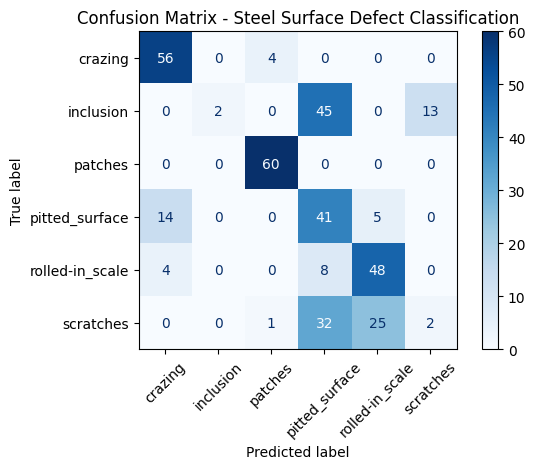

Confusion matrix saved.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

# Use the same class order used during model training
class_names = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(cmap="Blues", xticks_rotation=45, values_format="d")
plt.title("Confusion Matrix - Steel Surface Defect Classification")
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=200)
plt.show()

print("Confusion matrix saved.")

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

display(report_df.round(4))

report_df.to_csv(
    "/content/classification_report.csv"
)

print("Classification report saved successfully!")

,precision,recall,f1-score,support
crazing,0.7568,0.9333,0.8358,60.0000
inclusion,1.0000,0.0333,0.0645,60.0000
patches,0.9231,1.0000,0.9600,60.0000
pitted_surface,0.3254,0.6833,0.4409,60.0000
rolled-in_scale,0.6154,0.8000,0.6957,60.0000
scratches,0.1333,0.0333,0.0533,60.0000
accuracy,0.5806,0.5806,0.5806,0.5806
macro avg,0.6257,0.5806,0.5084,360.0000
weighted avg,0.6257,0.5806,0.5084,360.0000


Classification report saved successfully!


In [ ]:
import os

transfer_model.save("/content/steel_defect_model.keras")

print("Model saved successfully!")
print(
    "Model size:",
    round(
        os.path.getsize("/content/steel_defect_model.keras") / (1024 * 1024),
        2
    ),
    "MB"
)

Model saved successfully!
Model size: 9.28 MB


In [ ]:

# STEP 11 — Restore and save the final fine-tuned model

import os
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

checkpoint_path = "/content/best_mobilenet_finetuned.keras"

assert os.path.exists(checkpoint_path), (
    "Fine-tuned checkpoint not found. "
    "Run the fine-tuning cell first."
)

model_ft = tf.keras.models.load_model(
    checkpoint_path,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

# Make the fine-tuned model the final model used by the project
transfer_model = model_ft

final_model_path = "/content/steel_defect_model.keras"
transfer_model.save(final_model_path)

print("Final fine-tuned model restored and saved.")
print("Input shape:", transfer_model.input_shape)
print("Output shape:", transfer_model.output_shape)
print("Model size:", round(os.path.getsize(final_model_path) / (1024 * 1024), 2), "MB")
print("Class order:", class_names)


Final fine-tuned model restored and saved.
Input shape: (None, 160, 160, 3)
Output shape: (None, 6)
Model size: 9.21 MB
Class order: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [ ]:

# STEP 12 — Convert final model to TensorFlow Lite

import tensorflow as tf
import os

converter = tf.lite.TFLiteConverter.from_keras_model(
    transfer_model
)

converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

tflite_path = "/content/steel_defect_model.tflite"

with open(tflite_path, "wb") as f:
    f.write(tflite_model)

print("TFLite model saved successfully!")
print(
    "TFLite file size:",
    round(os.path.getsize(tflite_path) / (1024 * 1024), 2),
    "MB"
)


Saved artifact at '/tmp/tmpf02dwm8y'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='steel_image')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  132053127641040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365349392: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365345744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365349584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365344976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365345360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365353808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365351312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365354000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365345168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132053365349776

In [ ]:

import numpy as np
import tensorflow as tf

tflite_path = "/content/steel_defect_model.tflite"

interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Get one test image
images, labels = next(iter(test_rgb))
sample = images[:1].numpy().astype(input_details[0]["dtype"])

# Predict
interpreter.set_tensor(input_details[0]["index"], sample)
interpreter.invoke()

probabilities = interpreter.get_tensor(
    output_details[0]["index"]
)[0]

predicted_index = int(np.argmax(probabilities))

print("Actual class:", class_names[int(labels[0].numpy())])
print("Predicted class:", class_names[predicted_index])
print("Confidence:", f"{probabilities[predicted_index] * 100:.2f}%")
print("Probabilities:", np.round(probabilities, 4))

assert probabilities.shape == (6,)
assert np.all(np.isfinite(probabilities))

print("TFLite inference test passed!")


Actual class: crazing
Predicted class: crazing
Confidence: 99.99%
Probabilities: [0.9999 0.     0.     0.     0.     0.    ]
TFLite inference test passed!


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:

# Use the same sample for both models
keras_probs = transfer_model.predict(sample, verbose=0)[0]

interpreter.set_tensor(input_details[0]["index"], sample)
interpreter.invoke()
tflite_probs = interpreter.get_tensor(
    output_details[0]["index"]
)[0]

print("Keras predicted:", class_names[int(np.argmax(keras_probs))])
print("TFLite predicted:", class_names[int(np.argmax(tflite_probs))])
print("Maximum probability difference:",
      float(np.max(np.abs(keras_probs - tflite_probs))))

assert np.argmax(keras_probs) == np.argmax(tflite_probs), \
    "Predictions differ; investigate before deployment."

print("Keras and TFLite predictions match!")


Keras predicted: crazing
TFLite predicted: crazing
Maximum probability difference: 0.00013583898544311523
Keras and TFLite predictions match!


In [ ]:

from google.colab import files

files.download("/content/steel_defect_model.keras")
files.download("/content/steel_defect_model.tflite")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

%%writefile app.py
import os
import numpy as np
import streamlit as st
import tensorflow as tf
from PIL import Image

st.set_page_config(
    page_title="Steel Defect Classifier",
    page_icon="🔍",
    layout="centered"
)

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

MODEL_PATH = os.path.join(
    os.path.dirname(os.path.abspath(__file__)),
    "steel_defect_model.keras"
)

@st.cache_resource
def load_model():
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

    return tf.keras.models.load_model(
        MODEL_PATH,
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )

st.title("🔍 Steel Surface Defect Classification")
st.write(
    "Upload a steel-surface image to classify it into one "
    "of six defect categories."
)

if not os.path.exists(MODEL_PATH):
    st.error("Model file not found. Place steel_defect_model.keras beside app.py.")
    st.stop()

model = load_model()

uploaded_file = st.file_uploader(
    "Upload an image",
    type=["jpg", "jpeg", "png", "bmp"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")
    st.image(image, caption="Uploaded steel image", use_container_width=True)

    if st.button("Classify Defect", type="primary"):
        resized_image = image.resize((160, 160))
        image_array = np.asarray(resized_image, dtype=np.float32)
        image_array = np.expand_dims(image_array, axis=0)

        probabilities = model.predict(image_array, verbose=0)[0]
        predicted_index = int(np.argmax(probabilities))

        st.subheader("Prediction")
        st.success(f"Predicted class: {CLASS_NAMES[predicted_index]}")
        st.metric(
            "Model confidence",
            f"{probabilities[predicted_index] * 100:.2f}%"
        )

        st.subheader("Class probabilities")
        for i, name in enumerate(CLASS_NAMES):
            st.write(f"**{name}** — {probabilities[i] * 100:.2f}%")
            st.progress(float(probabilities[i]))

        st.caption(
            "Predictions are model estimates and should be validated "
            "before use in industrial quality-control decisions."
        )


Overwriting app.py


In [ ]:
!pip install -q streamlit

In [ ]:
import os

print("App exists:", os.path.exists("/content/app.py"))
print("Model exists:", os.path.exists("/content/steel_defect_model.keras"))

App exists: True
Model exists: True


In [ ]:

from google.colab.output import eval_js

# Generate a browser-accessible link to the running Streamlit app
url = eval_js("google.colab.kernel.proxyPort(8501)")
print("Open your Streamlit app here:")
print(url)


Open your Streamlit app here:
https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:

import os
import subprocess
import time
import requests

APP_PATH = "/content/app.py"
LOG_PATH = "/content/streamlit.log"

# Confirm the app file exists
if not os.path.exists(APP_PATH):
    print("ERROR: /content/app.py was not found.")
    print("Files in /content:", os.listdir("/content")[:40])
else:
    # Stop any old Streamlit process
    subprocess.run(
        ["pkill", "-f", "streamlit run"],
        capture_output=True
    )


In [ ]:
!pkill -f "streamlit run" || true

^C


In [ ]:
import os
import sys
import subprocess
import time
import requests

# Stop anything still listening on port 8501
!fuser -k 8501/tcp 2>/dev/null || true

log_path = "/content/streamlit.log"
log_file = open(log_path, "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "streamlit", "run", "/content/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--server.enableWebsocketCompression=false",
        "--browser.gatherUsageStats=false",
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True,
)

for i in range(20):
    time.sleep(1)
    try:
        response = requests.get(
            "http://127.0.0.1:8501/_stcore/health",
            timeout=2
        )
        if response.status_code == 200:
            print("SUCCESS: Streamlit is responding!")
            print("Health:", response.text)
            break
    except requests.RequestException:
        pass
else:
    print("Streamlit did not become ready. Check the logs below.")

log_file.close()

with open(log_path, "r") as f:
    print(f.read()[-4000:])

SUCCESS: Streamlit is responding!
Health: ok
2026-10-18 09:00:14.564 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.182.139.237:8501




In [ ]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print("Open this fresh link:", url)

Open this fresh link: https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
import os

# Find likely dataset folders
for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [
        ".git", "__pycache__", ".config"
    ]]

    if os.path.basename(root).lower() == "test":
        images = [
            f for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]
        if images:
            print("Test folder:", root)
            print("Example image:", os.path.join(root, images[0]))
            break
else:
    print("No test folder found under /content.")
    print("Check the dataset path used in your notebook.")

No test folder found under /content.
Check the dataset path used in your notebook.


In [ ]:
import os

print("Current working directory:", os.getcwd())
print("\nTop-level folders in /content:")
print(os.listdir("/content"))

# Search common locations for dataset folders and saved models
search_roots = ["/content", "/content/drive/MyDrive"]

for base in search_roots:
    if not os.path.exists(base):
        continue

    print(f"\nSearching in {base} ...")

    for root, dirs, files in os.walk(base):
        # Avoid unnecessary system folders
        dirs[:] = [
            d for d in dirs
            if d not in [".git", "__pycache__", ".config"]
        ]

        image_files = [
            f for f in files
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]

        model_files = [
            f for f in files
            if f.lower().endswith((".keras", ".h5", ".tflite"))
        ]

        if image_files and (
            "test" in root.lower()
            or "neu" in root.lower()
            or "steel" in root.lower()
        ):
            print("Possible dataset:", root)
            print("Sample images:", image_files[:3])

        if model_files:
            print("Saved model:", [
                os.path.join(root, f) for f in model_files
            ])

Current working directory: /content

Top-level folders in /content:
['.config', 'final_confusion_matrix.png', 'gradcam_result.png', 'best_cnn.keras', 'best_mobilenet.keras', 'best_mobilenet_finetuned.keras', 'classification_report.csv', 'app.py', 'steel_mobilenet_model.keras', 'steel_defect_model.keras', 'streamlit.log', 'steel_defect_model.tflite', 'steel_defect_model_finetuned.keras', 'model_comparison.csv', 'steel_project', 'steel_project.zip', 'steel_cnn_model.keras', 'confusion_matrix.png', 'evaluation_results.csv', 'sample_data']

Searching in /content ...
Saved model: ['/content/best_cnn.keras', '/content/best_mobilenet.keras', '/content/best_mobilenet_finetuned.keras', '/content/steel_mobilenet_model.keras', '/content/steel_defect_model.keras', '/content/steel_defect_model.tflite', '/content/steel_defect_model_finetuned.keras', '/content/steel_cnn_model.keras']
Possible dataset: /content/steel_project
Sample images: ['gradcam_result.png', 'confusion_matrix.png']
Saved model: ['

In [ ]:
import os

if os.path.exists("/content/drive/MyDrive"):
    print("Google Drive is mounted.")
    print("Files in MyDrive:")
    print(os.listdir("/content/drive/MyDrive")[:50])
else:
    print("Google Drive is not mounted.")

Google Drive is not mounted.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

path = "/content/drive/MyDrive"

print("Drive mounted:", os.path.exists(path))

if os.path.exists(path):
    print("\nFiles and folders in MyDrive:")
    for item in os.listdir(path):
        print(item)

Drive mounted: True

Files and folders in MyDrive:
Getting started.pdf
Classroom
Untitled spreadsheet.gsheet
Untitled folder
20200709_182454.jpg
20200709_182425.jpg
20200709_182359.jpg
20200709_182353.jpg
20200709_182330.jpg
20200709_182320.jpg
20200709_182305.jpg
20200709_182232.jpg
Daksh Bawa.pptx
Scanned_20200717-1447.pdf
worksheet 2.pdf
Scanned_20200717-1840.pdf
Hindi notebook.pdf
Scan 30 Jul 2020.pdf
Scanned_20200810-1755.pdf
FeeSlip (1).jpg
FeeSlip (1).gdoc
Scanned_20200912-1742.pdf
sst test.pdf
IMG-20201117-WA0114.jpg
Daksh (1).pdf
Scanned_20210121-1612.pdf
Scanned_20210121-1614.pdf
Param bawa.pdf
1667 (1).pdf
1667.pdf
subject-EEE reappear 1667.pdf
1667 param bawa.pdf
Scanned_20210223-1400.pdf
wts-zkrn-jri - May 11, 2021.pdf
Scanned_20210529-0936.pdf
Scanned_20210529-0940.pdf
Scanned_20210606-1257.pdf
Daksh.pdf
Adhar Card.pdf
Scanned_20211021-1040.pdf
SAVE_20211022_094743.jpg
w sheet.pdf
gravitation.pdf
work and energy.pdf
SAVE_20220322_215603.pdf
Scanned_20220812-1804.pdf
DOC-2

In [ ]:
import os

base = "/content/drive/MyDrive"

for root, dirs, files in os.walk(base):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__"]
    ]

    for f in files:
        if f.lower().endswith((
            ".keras", ".h5", ".tflite",
            ".zip", ".ipynb"
        )):
            print(os.path.join(root, f))

/content/drive/MyDrive/sleet_defect_cnn.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/SteelGuard_AI_Interface.ipynb
/content/drive/MyDrive/Colab Notebooks/Another copy of Untitled1 (1).ipynb
/content/drive/MyDrive/Colab Notebooks/Another copy of Untitled1.ipynb


In [ ]:
import os

base = "/content/drive/MyDrive"

extensions = (".keras", ".h5", ".tflite", ".zip", ".py")
found = []

for root, dirs, files in os.walk(base):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]

    for name in files:
        if name.lower().endswith(extensions):
            path = os.path.join(root, name)
            found.append(path)

if found:
    print("Project files found:")
    for path in found:
        print(path)
else:
    print("No saved model, dataset ZIP, or Python app found in Drive.")

No saved model, dataset ZIP, or Python app found in Drive.


In [ ]:
import json

notebook_path = "/content/drive/MyDrive/sleet_defect_cnn.ipynb"

with open(notebook_path, "r", encoding="utf-8") as f:
    nb = json.load(f)

print("Number of cells:", len(nb["cells"]))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if any(word in source.lower() for word in [
        "dataset", "kaggle", "load_model", "save",
        "mobilenet", "streamlit", "app.py",
        "train_dir", "test_dir", "zip"
    ]):
        print(f"\n--- Cell {i} ---")
        print(source[:1200])

Number of cells: 34

--- Cell 5 ---
import os
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

print("=== Searching entire Drive for folders with 'steel', 'sleet', 'defect', 'data' ===\n")

found = []
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for d in dirs:
        name = d.lower()
        if any(k in name for k in ['steel', 'sleet', 'defect', 'dataset', 'data', 'images']):
            full_path = os.path.join(root, d)
            found.append(full_path)
            print(full_path)

if not found:
    print("No matching folders found.")
else:
    print(f"\nFound {len(found)} possible folders.")

--- Cell 8 ---
DATASET_PATH = '/content/drive/MyDrive/steel_defect_AI/dataset'

print(os.path.exists(DATASET_PATH))
print(os.listdir(DATASET_PATH))

--- Cell 11 ---
import os

DATASET_PATH = '/content/drive/MyDrive/steel_defect_AI/dataset'

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("Dataset contents:", os.listdir(DATASET_

In [ ]:
%pip install -q kagglehub

import os
import kagglehub

path = kagglehub.dataset_download(
    "kaustubhdikshit/neu-surface-defect-database"
)

print("Dataset downloaded to:", path)

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level <= 3:
        print("  " * level + os.path.basename(root) + "/")
        for f in files[:3]:
            print("  " * (level + 1) + f)

Using Colab cache for faster access to the 'neu-surface-defect-database' dataset.
Dataset downloaded to: /kaggle/input/neu-surface-defect-database
neu-surface-defect-database/
  NEU-DET/
    validation/
      annotations/
        scratches_246.xml
        patches_258.xml
        crazing_241.xml
      images/
    train/
      annotations/
        patches_36.xml
        inclusion_147.xml
        crazing_200.xml
      images/


In [ ]:
import os

DATASET_PATH = "/kaggle/input/neu-surface-defect-database/NEU-DET"

for split in ["train", "validation"]:
    image_dir = os.path.join(DATASET_PATH, split, "images")
    annotation_dir = os.path.join(DATASET_PATH, split, "annotations")

    print(f"\n{split}:")
    print("Images folder exists:", os.path.isdir(image_dir))
    print("Annotations folder exists:", os.path.isdir(annotation_dir))

    if os.path.isdir(image_dir):
        images = [
            f for f in os.listdir(image_dir)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ]
        print("Image count:", len(images))
        print("Examples:", images[:5])

print("\nSaved models:")
for path in [
    "/content/steelguard_model.keras",
    "/content/steel_defect_model.keras",
    "/content/best_mobilenet.keras",
]:
    print(path, "FOUND" if os.path.exists(path) else "not found")


train:
Images folder exists: True
Annotations folder exists: True
Image count: 0
Examples: []

validation:
Images folder exists: True
Annotations folder exists: True
Image count: 0
Examples: []

Saved models:
/content/steelguard_model.keras not found
/content/steel_defect_model.keras FOUND
/content/best_mobilenet.keras FOUND


In [ ]:

import os

print("Files in /content:")
print(os.listdir("/content"))

print("\nChecking common dataset locations:")
for path in [
    "/content/NEU-DET",
    "/content/NEU-DET/train",
    "/content/NEU-DET/validation",
    "/content/drive/MyDrive",
    "/content/steel_defect_model.keras",
    "/content/best_mobilenet.keras",
    "/content/app.py"
]:
    print(f"{path}: {os.path.exists(path)}")


Files in /content:
['.config', 'final_confusion_matrix.png', 'gradcam_result.png', 'best_cnn.keras', 'best_mobilenet.keras', 'best_mobilenet_finetuned.keras', 'classification_report.csv', 'app.py', 'steel_mobilenet_model.keras', 'steel_defect_model.keras', 'streamlit.log', 'steel_defect_model.tflite', 'steel_defect_model_finetuned.keras', 'model_comparison.csv', 'steel_project', 'steel_project.zip', 'steel_cnn_model.keras', 'confusion_matrix.png', 'drive', 'evaluation_results.csv', 'sample_data']

Checking common dataset locations:
/content/NEU-DET: False
/content/NEU-DET/train: False
/content/NEU-DET/validation: False
/content/drive/MyDrive: True
/content/steel_defect_model.keras: True
/content/best_mobilenet.keras: True
/content/app.py: True


In [ ]:

from google.colab import drive
drive.mount("/content/drive")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    if "train" in dirs and "validation" in dirs:
        print("Possible dataset folder:", root)
    dirs[:] = [
        d for d in dirs
        if d not in [".ipynb_checkpoints", "node_modules"]
    ]


In [ ]:

import os

for root, dirs, files in os.walk("/content"):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]
    if image_files:
        print(f"\nFolder: {root}")
        print("Image count here:", len(image_files))
        print("Examples:", image_files[:5])



Folder: /content
Image count here: 3
Examples: ['final_confusion_matrix.png', 'gradcam_result.png', 'confusion_matrix.png']

Folder: /content/steel_project
Image count here: 2
Examples: ['gradcam_result.png', 'confusion_matrix.png']

Folder: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/dataset/extracted/NEU-DET/train/images/crazing
Image count here: 240
Examples: ['crazing_1.jpg', 'crazing_10.jpg', 'crazing_100.jpg', 'crazing_101.jpg', 'crazing_102.jpg']

Folder: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/dataset/extracted/NEU-DET/train/images/inclusion
Image count here: 240
Examples: ['inclusion_1.jpg', 'inclusion_10.jpg', 'inclusion_100.jpg', 'inclusion_101.jpg', 'inclusion_102.jpg']

Folder: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/dataset/extracted/NEU-DET/train/images/patches
Image count here: 240
Examples: ['patches_1.jpg', 'patches_10.jpg', '

In [ ]:

import os

PROJECT_DIR = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/"
    "steel_defect_AI"
)

DATASET_DIR = os.path.join(
    PROJECT_DIR, "dataset", "extracted", "NEU-DET"
)

train_dir = os.path.join(DATASET_DIR, "train", "images")
val_dir = os.path.join(DATASET_DIR, "validation", "images")

# Confirm the folders and count images by class
classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

for split, folder in [("Train", train_dir), ("Validation", val_dir)]:
    print(f"\n{split}: {folder}")
    for cls in classes:
        class_dir = os.path.join(folder, cls)
        count = (
            len([
                f for f in os.listdir(class_dir)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
            ])
            if os.path.isdir(class_dir) else 0
        )
        print(f"  {cls}: {count} images")



Train: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/dataset/extracted/NEU-DET/train/images
  crazing: 240 images
  inclusion: 240 images
  patches: 240 images
  pitted_surface: 240 images
  rolled-in_scale: 240 images
  scratches: 240 images

Validation: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/dataset/extracted/NEU-DET/validation/images
  crazing: 60 images
  inclusion: 60 images
  patches: 60 images
  pitted_surface: 60 images
  rolled-in_scale: 60 images
  scratches: 60 images


In [ ]:

import os
import tensorflow as tf

print("Train directory exists:", os.path.isdir(train_dir))
print("Validation directory exists:", os.path.isdir(val_dir))

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(160, 160),
    batch_size=32,
    label_mode="int",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(160, 160),
    batch_size=32,
    label_mode="int",
    shuffle=False
)

print("Classes:", train_ds.class_names)
print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())


Train directory exists: True
Validation directory exists: True
Found 1440 files belonging to 6 classes.
Found 360 files belonging to 6 classes.
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Training batches: 45
Validation batches: 12


In [ ]:

import os
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

def build_transfer_model():
    base_model = MobileNetV2(
        input_shape=(160, 160, 3),
        include_top=False,
        weights="imagenet"
    )
    base_model.trainable = False

    inputs = layers.Input(shape=(160, 160, 3), name="steel_image")

    x = layers.RandomRotation(0.05)(inputs)
    x = layers.RandomTranslation(0.05, 0.05)(x)
    x = layers.RandomZoom(0.10)(x)

    # MobileNetV2 preprocessing: [0,255] -> [-1,1]
    x = layers.Rescaling(
        scale=1.0 / 127.5,
        offset=-1.0,
        name="mobilenet_preprocessing"
    )(x)

    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="defect_predictions"
    )(x)

    model = models.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

transfer_model = build_transfer_model()
transfer_model.summary()


Model: "functional_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ steel_image (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_3               │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_3            │ (None, 160, 160, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_3 (RandomZoom)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 160, 160, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ defect_predictions (Dense)      │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
import os
import tensorflow as tf

MODEL_DIR = "/content/steel_project/models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("Model folder:", MODEL_DIR)

Model folder: /content/steel_project/models


In [ ]:

BEST_MODEL_PATH = os.path.join(MODEL_DIR, "best_mobilenet.keras")
FINAL_MODEL_PATH = os.path.join(MODEL_DIR, "steel_defect_model.keras")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        BEST_MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

transfer_model.save(FINAL_MODEL_PATH)
print("Saved final model:", FINAL_MODEL_PATH)


Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.5114 - loss: 1.3116
Epoch 1: val_loss improved from None to 0.35271, saving model to /content/steel_project/models/best_mobilenet.keras

Epoch 1: finished saving model to /content/steel_project/models/best_mobilenet.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 317s 7s/step - accuracy: 0.7319 - loss: 0.7687 - val_accuracy: 0.9278 - val_loss: 0.3527 - learning_rate: 0.0010
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 818ms/step - accuracy: 0.9623 - loss: 0.1789
Epoch 2: val_loss improved from 0.35271 to 0.23902, saving model to /content/steel_project/models/best_mobilenet.keras

Epoch 2: finished saving model to /content/steel_project/models/best_mobilenet.keras
45/45 ━━━━━━━━━━━━━━━━━━━━ 46s 1s/step - accuracy: 0.9674 - loss: 0.1534 - val_accuracy: 0.9361 - val_loss: 0.2390 - learning_rate: 0.0010
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 807ms/step - accuracy: 0.9839 - loss: 0.0994
Epoch 3: val_loss improved from 0.23902 to 0.20473, saving 

In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    compile=False
)

y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

probabilities = best_model.predict(val_ds)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred))


12/12 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step
                 precision    recall  f1-score   support

        crazing       0.92      1.00      0.96        60
      inclusion       1.00      0.83      0.91        60
        patches       0.97      1.00      0.98        60
 pitted_surface       0.95      0.88      0.91        60
rolled-in_scale       0.90      1.00      0.94        60
      scratches       0.97      0.97      0.97        60

       accuracy                           0.95       360
      macro avg       0.95      0.95      0.95       360
   weighted avg       0.95      0.95      0.95       360

Confusion matrix:
[[60  0  0  0  0  0]
 [ 0 50  2  3  3  2]
 [ 0  0 60  0  0  0]
 [ 5  0  0 53  2  0]
 [ 0  0  0  0 60  0]
 [ 0  0  0  0  2 58]]


In [ ]:

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Use the best checkpoint from training
best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH,
    compile=False
)

y_true = np.concatenate([
    labels.numpy() for _, labels in val_ds
])

probabilities = best_model.predict(val_ds)
y_pred = np.argmax(probabilities, axis=1)

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(class_names)))
)

os.makedirs(MODEL_DIR, exist_ok=True)

with open(os.path.join(MODEL_DIR, "classification_report.json"), "w") as f:
    json.dump(report, f, indent=4)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(os.path.join(MODEL_DIR, "confusion_matrix.csv"))

print(f"Validation accuracy: {accuracy_score(y_true, y_pred):.2%}")
print("Evaluation results saved in:", MODEL_DIR)


12/12 ━━━━━━━━━━━━━━━━━━━━ 13s 668ms/step
Validation accuracy: 94.72%
Evaluation results saved in: /content/steel_project/models


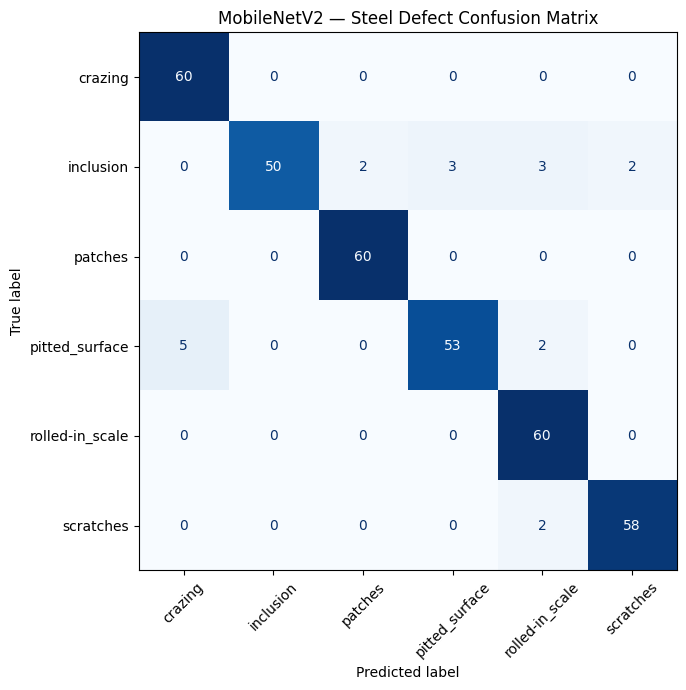

In [ ]:

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(9, 7))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

ax.set_title("MobileNetV2 — Steel Defect Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:

# Test loading the final saved model from Drive
final_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

# Test one batch of images
images, labels = next(iter(val_ds))
predictions = final_model.predict(images[:5], verbose=0)

for i in range(5):
    predicted_class = class_names[np.argmax(predictions[i])]
    actual_class = class_names[int(labels[i])]
    confidence = float(np.max(predictions[i]))

    print(
        f"Image {i+1}: Actual={actual_class} | "
        f"Predicted={predicted_class} | "
        f"Confidence={confidence:.2%}"
    )

print("\nFinal model loads and predicts successfully.")
print("Model path:", FINAL_MODEL_PATH)


Image 1: Actual=crazing | Predicted=crazing | Confidence=99.76%
Image 2: Actual=crazing | Predicted=crazing | Confidence=99.71%
Image 3: Actual=crazing | Predicted=crazing | Confidence=98.52%
Image 4: Actual=crazing | Predicted=crazing | Confidence=99.08%
Image 5: Actual=crazing | Predicted=crazing | Confidence=99.99%

Final model loads and predicts successfully.
Model path: /content/steel_project/models/steel_defect_model.keras


In [ ]:

!pip install -q streamlit pyngrok


In [ ]:

%%writefile /content/app.py
import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

st.set_page_config(
    page_title="SteelGuard AI",
    page_icon="🔍",
    layout="wide"
)

MODEL_PATH = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        MODEL_PATH,
        compile=False
    )

st.title("🔍 SteelGuard AI")
st.subheader("Steel Surface Defect Classification")
st.write(
    "Upload a steel-surface image to classify its defect "
    "using a MobileNetV2 deep-learning model."
)

try:
    model = load_model()
except Exception as e:
    st.error(f"Could not load model: {e}")
    st.stop()

uploaded_file = st.file_uploader(
    "Upload a steel image",
    type=["jpg", "jpeg", "png", "bmp"]
)

if uploaded_file is not None:
    image = Image.open(uploaded_file).convert("RGB")

    col1, col2 = st.columns(2)

    with col1:
        st.image(image, caption="Uploaded image", use_container_width=True)

    resized = image.resize((160, 160))
    image_array = np.array(resized, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probabilities = model.predict(image_array, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))
    predicted_class = CLASS_NAMES[predicted_index]
    confidence = float(probabilities[predicted_index])

    with col2:
        st.success(f"Predicted defect: **{predicted_class}**")
        st.metric("Prediction confidence", f"{confidence:.2%}")

        st.write("Class probabilities")
        chart_data = {
            "Defect class": CLASS_NAMES,
            "Probability": probabilities
        }
        st.bar_chart(
            chart_data,
            x="Defect class",
            y="Probability"
        )

    st.caption(
        "Predictions are model estimates and should be reviewed "
        "before making industrial quality-control decisions."
    )


Overwriting /content/app.py


In [ ]:

import subprocess
import time
import os

# Stop an earlier Streamlit process if one exists
subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run /content/app.py' || true"],
    check=False
)

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0",
        "--server.headless", "true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit process ID:", process.pid)
print("Log file: /content/streamlit.log")

with open("/content/streamlit.log") as f:
    print(f.read()[-4000:])


Streamlit process ID: 49061
Log file: /content/streamlit.log





In [ ]:

from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print("Open your SteelGuard AI app here:")
print(url)


Open your SteelGuard AI app here:
https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:

import requests
import os

try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("Streamlit health status:", response.status_code)
    print("Response:", response.text)
except Exception as e:
    print("Connection error:", repr(e))

print("\nRecent Streamlit logs:")
if os.path.exists("/content/streamlit.log"):
    with open("/content/streamlit.log") as f:
        print(f.read()[-5000:])


Streamlit health status: 200
Response: ok

Recent Streamlit logs:


2026-10-17 19:12:51.727 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.82.88.247:8501

2026-10-17 19:14:05.372 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-kkb-usw1b2-1j3cqp2n0yt3b-b.us-west1-2.prod.colab.dev, host=gpu-t4-s-kkb-usw1b2-1j3cqp2n0yt3b.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-10-17 19:14:08.450 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-kkb-usw1b2-1j3cqp2n0yt3b-b.us-west1-2.prod.colab.dev, host=gpu-t4-s-kkb-usw1b2-1j3cqp2n0yt3b.us-west1-b.c.codatalab-user-runtimes.internal:8007
2026-10-17 19:14:10.596 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-gpu-t4-s-kkb-usw1b2-1j3cqp2n0yt3b-b.us-west1-2.p

In [ ]:

%%writefile /content/app.py
import os
import numpy as np
import streamlit as st
import tensorflow as tf
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

st.set_page_config(
    page_title="Steel Surface Defect Inspection",
    page_icon="🏭",
    layout="wide"
)

MODEL_PATH = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(
        MODEL_PATH,
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )

st.title("🏭 Steel Surface Defect Inspection")
st.write("Upload a steel surface image to classify its defect.")

if not os.path.isfile(MODEL_PATH):
    st.error("Model file not found. Check Google Drive is mounted and the path is correct.")
    st.stop()

try:
    model = load_model()
except Exception as e:
    st.error(f"Model loading failed: {e}")
    st.stop()

uploaded_file = st.file_uploader(
    "Upload a steel image",
    type=["jpg", "jpeg", "png", "bmp"]
)

if uploaded_file is not None:
    try:
        image = Image.open(uploaded_file).convert("RGB")
        st.image(image, caption="Uploaded steel image", width=400)

        if st.button("Inspect Surface", type="primary"):
            resized = image.resize((160, 160))
            batch = np.expand_dims(
                np.asarray(resized, dtype=np.float32), axis=0
            )

            # The model already contains its preprocessing layer.
            probabilities = model.predict(batch, verbose=0)[0]
            predicted_index = int(np.argmax(probabilities))

            st.success(f"Predicted defect: {CLASS_NAMES[predicted_index]}")
            st.metric(
                "Model confidence",
                f"{float(probabilities[predicted_index]):.2%}"
            )

            st.caption(
                "Research prototype. Validate on representative "
                "industrial images before production use."
            )
    except Exception as e:
        st.error(f"Could not process the image: {e}")


Overwriting /content/app.py


In [ ]:
import subprocess
import time

log_file = open("/content/streamlit.log", "w")
process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port", "8501",
        "--server.address", "0.0.0.0"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(8)
print("Still running:", process.poll() is None)
print(open("/content/streamlit.log").read()[-2000:])

Still running: False
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                   

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:

# Stop the existing Streamlit process
import subprocess
import time

subprocess.run(
    ["bash", "-lc", "pkill -f 'streamlit run /content/app.py' || true"],
    check=False
)


CompletedProcess(args=['bash', '-lc', "pkill -f 'streamlit run /content/app.py' || true"], returncode=-15)

In [ ]:

import subprocess
import time

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Streamlit PID:", process.pid)

with open("/content/streamlit.log") as f:
    print(f.read()[-3000:])


Streamlit PID: 13969
2026-10-17 19:17:36.196 Uvicorn server started on 0.0.0.0:8501



In [ ]:

from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(8501)")
print(url)


https://8501-gpu-t4-s-kkb-usw1b2-1j3cqp2n0yt3b-b.us-west1-2.prod.colab.dev


In [ ]:
!streamlit run /content/app.py --server.port 8501



2026-10-18 09:43:55.172 Port 8501 is not available


In [ ]:
!pkill -f "streamlit run /content/app.py"

In [ ]:
import subprocess
import time

with open("/content/streamlit.log", "w") as log:
    process = subprocess.Popen(
        [
            "streamlit", "run", "/content/app.py",
            "--server.port", "8501",
            "--server.address", "0.0.0.0"
        ],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(5)

print("Running:", process.poll() is None)
print(open("/content/streamlit.log").read()[-2000:])

Running: True


2026-10-18 09:45:00.980 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.182.139.237:8501




In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
import os

for class_name in sorted(os.listdir(val_dir)):
    class_path = os.path.join(val_dir, class_name)
    if os.path.isdir(class_path):
        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ])
        print(f"{class_name}: {count} images")

crazing: 60 images
inclusion: 60 images
patches: 60 images
pitted_surface: 60 images
rolled-in_scale: 60 images
scratches: 60 images


Validation Accuracy: 94.72%

Classification Report:
                 precision    recall  f1-score   support

        crazing      0.923     1.000     0.960        60
      inclusion      1.000     0.833     0.909        60
        patches      0.968     1.000     0.984        60
 pitted_surface      0.946     0.883     0.914        60
rolled-in_scale      0.896     1.000     0.945        60
      scratches      0.967     0.967     0.967        60

       accuracy                          0.947       360
      macro avg      0.950     0.947     0.946       360
   weighted avg      0.950     0.947     0.946       360



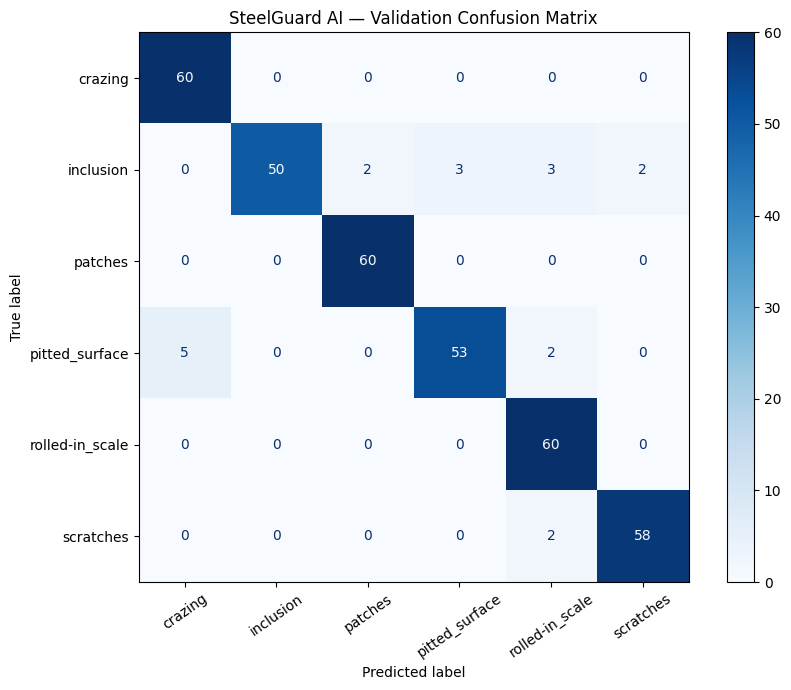

Saved: confusion_matrix.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)

# Define classes in the same order used by the dataset/model
CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

# Reuse predictions if they already exist
y_true = np.concatenate([
    labels.numpy() for images, labels in val_ds
])

# Reuse y_pred if available; otherwise generate predictions
if "y_pred" not in globals():
    y_prob = final_model.predict(val_ds, verbose=1)
    y_pred = np.argmax(y_prob, axis=1)

print(f"Validation Accuracy: {accuracy_score(y_true, y_pred):.2%}")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0
))

# Plot and save confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(CLASS_NAMES)))
)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(ax=ax, cmap="Blues", xticks_rotation=35, values_format="d")

ax.set_title("SteelGuard AI — Validation Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: confusion_matrix.png")

In [ ]:
import os

CLASS_NAMES = sorted([
    name for name in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, name))
])

print("Class order:")
for i, name in enumerate(CLASS_NAMES):
    print(i, ":", name)

Class order:
0 : crazing
1 : inclusion
2 : patches
3 : pitted_surface
4 : rolled-in_scale
5 : scratches


12/12 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step
Validation Accuracy: 94.72%

Classification Report:
                 precision    recall  f1-score   support

        crazing      0.923     1.000     0.960        60
      inclusion      1.000     0.833     0.909        60
        patches      0.968     1.000     0.984        60
 pitted_surface      0.946     0.883     0.914        60
rolled-in_scale      0.896     1.000     0.945        60
      scratches      0.967     0.967     0.967        60

       accuracy                          0.947       360
      macro avg      0.950     0.947     0.946       360
   weighted avg      0.950     0.947     0.946       360



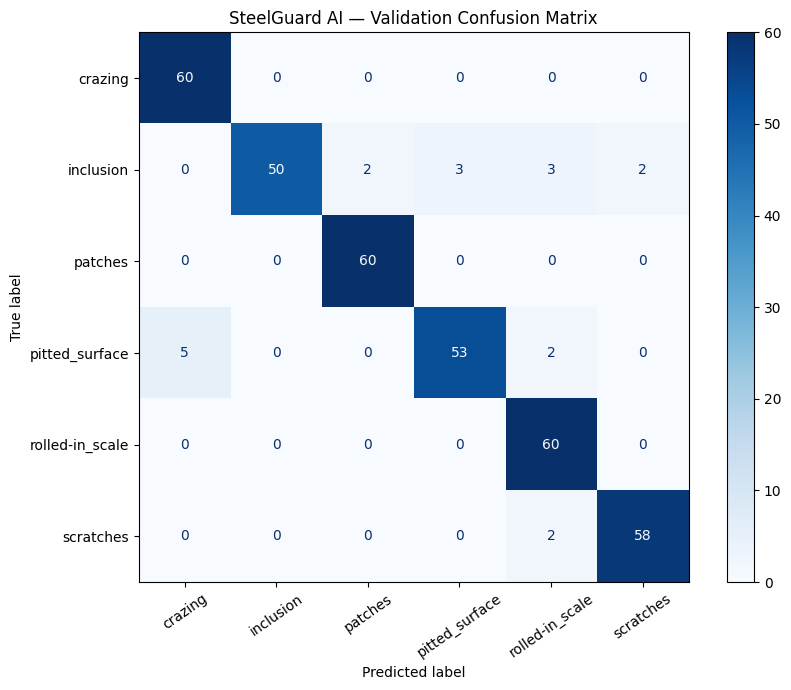

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

# Actual validation labels
y_true = np.concatenate([y.numpy() for x, y in val_ds])

# Predict again to ensure predictions align with validation dataset order
y_prob = final_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(f"Validation Accuracy: {accuracy_score(y_true, y_pred):.2%}")
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(ax=ax, cmap="Blues", xticks_rotation=35, values_format="d")
ax.set_title("SteelGuard AI — Validation Confusion Matrix")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

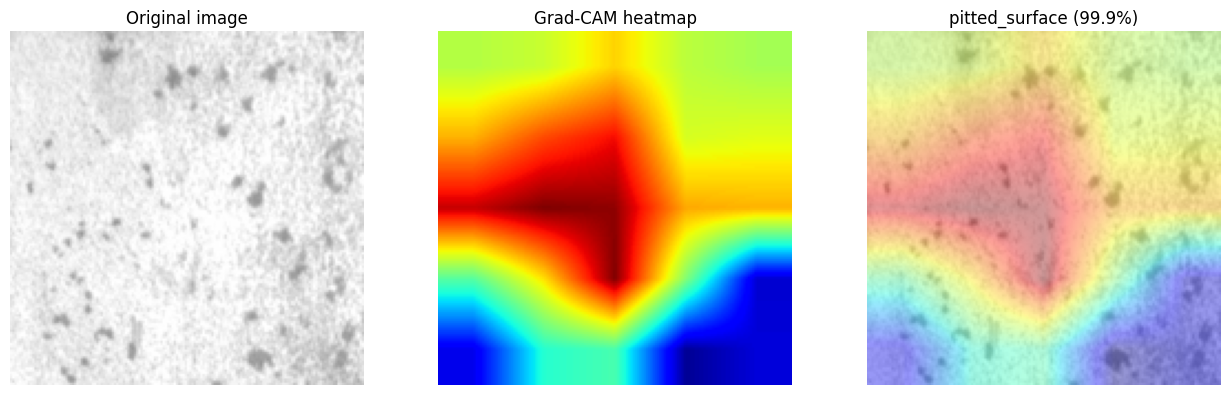

Predicted class: pitted_surface
Confidence: 99.91%
Saved gradcam_example.png


In [ ]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

model = final_model

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]

# 1. Locate the MobileNetV2 backbone
base_model = next(
    layer for layer in model.layers
    if isinstance(layer, tf.keras.Model)
    and "mobilenetv2" in layer.name.lower()
)

# 2. Locate the final convolutional feature layer
last_conv_layer = base_model.get_layer("out_relu")

# Both outputs belong to the backbone's own graph
feature_model = tf.keras.Model(
    inputs=base_model.input,
    outputs=[last_conv_layer.output, base_model.output]
)

# 3. Select a validation image
class_name = "pitted_surface"
image_folder = os.path.join(val_dir, class_name)

image_files = sorted([
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

if not image_files:
    raise ValueError(f"No images found in {image_folder}")

image_path = os.path.join(image_folder, image_files[0])
img = Image.open(image_path).convert("RGB").resize((160, 160))
input_tensor = tf.convert_to_tensor(
    np.asarray(img, dtype=np.float32)[None, ...]
)

# 4. Reproduce preprocessing and calculate Grad-CAM
with tf.GradientTape() as tape:
    x = input_tensor

    # Apply outer-model preprocessing layers before MobileNetV2
    for layer in model.layers:
        if layer is base_model:
            break
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        x = layer(x, training=False)

    conv_outputs, backbone_output = feature_model(x, training=False)

    # Pass features through the model's classification head
    predictions = backbone_output
    backbone_index = model.layers.index(base_model)

    for layer in model.layers[backbone_index + 1:]:
        predictions = layer(predictions, training=False)

    class_index = tf.argmax(predictions[0], output_type=tf.int32)
    class_score = tf.gather(predictions[0], class_index)

grads = tape.gradient(class_score, conv_outputs)

if grads is None:
    raise ValueError(
        "Gradients are unavailable. Please send me the model layer names."
    )

# 5. Create the heatmap
weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)[0]
heatmap = tf.maximum(heatmap, 0)
heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
heatmap = tf.image.resize(
    heatmap[..., tf.newaxis], (160, 160)
).numpy().squeeze()

# 6. Display prediction and explanation
probabilities = predictions.numpy()[0]
pred_idx = int(np.argmax(probabilities))
predicted_class = CLASS_NAMES[pred_idx]
confidence = float(probabilities[pred_idx])

plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img)
plt.imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
plt.title(f"{predicted_class} ({confidence:.1%})")
plt.axis("off")

plt.tight_layout()
plt.savefig("gradcam_example.png", dpi=200, bbox_inches="tight")
plt.show()

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2%}")
print("Saved gradcam_example.png")

In [ ]:
for i, layer in enumerate(final_model.layers):
    print(i, layer.name, type(layer).__name__)

0 steel_image InputLayer
1 random_rotation_3 RandomRotation
2 random_translation_3 RandomTranslation
3 random_zoom_3 RandomZoom
4 mobilenet_preprocessing Rescaling
5 mobilenetv2_1.00_160 Functional
6 global_average_pooling2d_2 GlobalAveragePooling2D
7 dropout_3 Dropout
8 defect_predictions Dense


In [ ]:

%%writefile /content/app.py
import os
import numpy as np
import streamlit as st
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image

st.set_page_config(
    page_title="SteelGuard AI",
    page_icon="🔍",
    layout="wide"
)

MODEL_PATH = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--Dbqlt/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]

IMG_SIZE = (160, 160)

@st.cache_resource
def load_model():
    return tf.keras.models.load_model(MODEL_PATH, compile=False)

def make_gradcam(model, image_array):
    # Find the nested MobileNetV2 backbone
    backbone = next(
        layer for layer in model.layers
        if isinstance(layer, tf.keras.Model)
        and "mobilenetv2" in layer.name.lower()
    )

    conv_layer = backbone.get_layer("out_relu")

    # Build feature extractor inside the backbone's own graph
    feature_model = tf.keras.Model(
        inputs=backbone.inputs,
        outputs=[conv_layer.output, backbone.output]
    )

    # Apply outer preprocessing layers before the backbone
    x = tf.convert_to_tensor(image_array, dtype=tf.float32)
    for layer in model.layers:
        if layer is backbone:
            break
        if isinstance(layer, tf.keras.layers.InputLayer):
            continue
        x = layer(x, training=False)

    with tf.GradientTape() as tape:
        conv_outputs, backbone_features = feature_model(
            x, training=False
        )

        # Follow the model's actual classification head
        predictions = backbone_features
        backbone_index = model.layers.index(backbone)
        for layer in model.layers[backbone_index + 1:]:
            predictions = layer(predictions, training=False)

        class_index = tf.argmax(predictions[0], output_type=tf.int32)
        score = predictions[0, class_index]

    gradients = tape.gradient(score, conv_outputs)
    if gradients is None:
        raise ValueError("Could not calculate Grad-CAM gradients.")

    weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
    heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)[0]
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis], IMG_SIZE
    ).numpy().squeeze()

    return predictions.numpy()[0], heatmap

st.title("🔍 SteelGuard AI")
st.subheader("Steel Surface Defect Classification")
st.write(
    "Upload a steel surface image to classify its defect "
    "and visualize the regions influencing the prediction."
)

try:
    model = load_model()
except Exception as exc:
    st.error(f"Could not load model: {exc}")
    st.stop()

uploaded_file = st.file_uploader(
    "Upload a steel image",
    type=["jpg", "jpeg", "png", "bmp"]
)

if uploaded_file:
    try:
        image = Image.open(uploaded_file).convert("RGB")
        resized = image.resize(IMG_SIZE)
        image_array = np.asarray(resized, dtype=np.float32)[None, ...]

        probabilities, heatmap = make_gradcam(model, image_array)
        pred_idx = int(np.argmax(probabilities))
        predicted_class = CLASS_NAMES[pred_idx]
        confidence = float(probabilities[pred_idx])

        st.divider()
        col1, col2 = st.columns(2)

        with col1:
            st.image(image, caption="Original image", use_container_width=True)
            st.success(f"Prediction: {predicted_class}")
            st.metric("Prediction confidence", f"{confidence:.2%}")

        with col2:
            fig, ax = plt.subplots(figsize=(6, 5))
            ax.imshow(resized)
            ax.imshow(heatmap, cmap="jet", alpha=0.4, vmin=0, vmax=1)
            ax.set_title("Grad-CAM explanation")
            ax.axis("off")
            fig.tight_layout()
            st.pyplot(fig)
            plt.close(fig)

        st.subheader("Class probabilities")
        st.bar_chart({
            "Defect class": CLASS_NAMES,
            "Probability": probabilities
        }, x="Defect class", y="Probability")

        st.caption(
            "Grad-CAM is an explanatory aid, not proof of correctness. "
            "Review predictions before industrial quality-control decisions."
        )

    except Exception as exc:
        st.error(f"Prediction or Grad-CAM failed: {exc}")


Overwriting /content/app.py


In [ ]:
import subprocess
import time
import os
import signal

# Stop only the previously recorded Streamlit process, if available.
try:
    process.terminate()
    process.wait(timeout=5)
except Exception:
    pass

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)
print("Streamlit PID:", process.pid)

from google.colab.output import eval_js
print("Open your updated app:")
print(eval_js("google.colab.kernel.proxyPort(8501)"))

Streamlit PID: 52490
Open your updated app:
https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
import os

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))
print("Model folder exists:", os.path.exists(
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--Dbqlt/"
    "steel_defect_AI/models"
))

Drive mounted: True
Model folder exists: False


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

MODEL_DIR = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--Dbqlt/"
    "steel_defect_AI/models"
)

if os.path.isdir(MODEL_DIR):
    print("Files found:", os.listdir(MODEL_DIR))
else:
    print("Model directory not found:", MODEL_DIR)

Model directory not found: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--Dbqlt/steel_defect_AI/models


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive"):
    for file in files:
        if file in ("steel_defect_model.keras", "best_mobilenet.keras"):
            print(os.path.join(root, file))

/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/best_mobilenet.keras
/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras


In [ ]:
app_path = "/content/app.py"

with open(app_path, "r") as f:
    code = f.read()

old_path = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--Dbqlt/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

new_path = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

if old_path in code:
    code = code.replace(old_path, new_path)
    with open(app_path, "w") as f:
        f.write(code)
    print("Model path corrected.")
elif new_path in code:
    print("Model path is already correct.")
else:
    print("Couldn't find the expected model path. Current MODEL_PATH section:")
    print(code[code.find("MODEL_PATH"):code.find("MODEL_PATH") + 300])

Couldn't find the expected model path. Current MODEL_PATH section:
MODEL_PATH = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--Dbqlt/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

CLASS_NAMES = [
    "crazing", "inclusion", "patches",
    "pitted_surface", "rolled-in_scale", "scratches"
]

IMG_SIZE = (160, 160)

@st.cach


In [ ]:
import os
import tensorflow as tf

MODEL_PATH = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

print("File exists:", os.path.isfile(MODEL_PATH))

test_model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("Model loaded successfully!")

File exists: True
Model loaded successfully!


In [ ]:
import subprocess
import time
from google.colab.output import eval_js

# Stop the previous app using its recorded process handle
try:
    process.terminate()
    process.wait(timeout=5)
except Exception:
    pass

log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--browser.gatherUsageStats=false"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("App PID:", process.pid)
print("Open updated app:")
print(eval_js("google.colab.kernel.proxyPort(8501)"))

with open("/content/streamlit.log") as f:
    print(f.read()[-2000:])

App PID: 52768
Open updated app:
https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev
2026-10-18 09:49:15.323 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.182.139.237:8501




In [ ]:

import os
import tensorflow as tf
import time
import numpy as np

MODEL_PATH = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/"
    "steel_defect_AI/models/steel_defect_model.keras"
)

MODEL_DIR = os.path.dirname(MODEL_PATH)
TFLITE_PATH = os.path.join(MODEL_DIR, "steel_defect_model.tflite")

# Load the trained Keras model
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
print("Keras model loaded successfully.")

# Convert to TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the converted model
with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)

print("TensorFlow Lite model saved:", TFLITE_PATH)
print(f"TFLite model size: {os.path.getsize(TFLITE_PATH) / (1024**2):.2f} MB")


Keras model loaded successfully.
Saved artifact at '/tmp/tmpd4jqxhdb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='steel_image')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  132052849565840: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849567376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849567184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849567568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849566032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849566800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849568336: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849568144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849568528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132052849566224: TensorSpec(shape=(), dtype=tf.resou

In [ ]:

KERAS_SIZE = os.path.getsize(MODEL_PATH)
TFLITE_SIZE = os.path.getsize(TFLITE_PATH)

print(f"Keras model: {KERAS_SIZE / (1024**2):.2f} MB")
print(f"TFLite model: {TFLITE_SIZE / (1024**2):.2f} MB")

reduction = (1 - TFLITE_SIZE / KERAS_SIZE) * 100
print(f"Size reduction: {reduction:.2f}%")


Keras model: 9.27 MB
TFLite model: 8.50 MB
Size reduction: 8.30%


In [ ]:

# Create a TFLite interpreter
interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input shape:", input_details[0]["shape"])
print("Input dtype:", input_details[0]["dtype"])
print("Output shape:", output_details[0]["shape"])

# Use one validation batch
images, labels = next(iter(val_ds))
sample = images[:1].numpy().astype(input_details[0]["dtype"])

interpreter.set_tensor(input_details[0]["index"], sample)
interpreter.invoke()

tflite_probs = interpreter.get_tensor(output_details[0]["index"])
tflite_pred = int(np.argmax(tflite_probs[0]))

print("Actual class index:", int(labels[0].numpy()))
print("Predicted class index:", tflite_pred)
print("Predicted class:", CLASS_NAMES[tflite_pred])
print(f"Confidence: {tflite_probs[0][tflite_pred]:.2%}")


Input shape: [  1 160 160   3]
Input dtype: <class 'numpy.float32'>
Output shape: [1 6]
Actual class index: 0
Predicted class index: 0
Predicted class: crazing
Confidence: 99.51%


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:

KERAS_SIZE = os.path.getsize(MODEL_PATH)
TFLITE_SIZE = os.path.getsize(TFLITE_PATH)

print(f"Keras model: {KERAS_SIZE / (1024**2):.2f} MB")
print(f"TFLite model: {TFLITE_SIZE / (1024**2):.2f} MB")

reduction = (1 - TFLITE_SIZE / KERAS_SIZE) * 100
print(f"Size reduction: {reduction:.2f}%")


Keras model: 9.27 MB
TFLite model: 8.50 MB
Size reduction: 8.30%


In [ ]:

# Create a TFLite interpreter
interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input shape:", input_details[0]["shape"])
print("Input dtype:", input_details[0]["dtype"])
print("Output shape:", output_details[0]["shape"])

# Use one validation batch
images, labels = next(iter(val_ds))
sample = images[:1].numpy().astype(input_details[0]["dtype"])

interpreter.set_tensor(input_details[0]["index"], sample)
interpreter.invoke()

tflite_probs = interpreter.get_tensor(output_details[0]["index"])
tflite_pred = int(np.argmax(tflite_probs[0]))

print("Actual class index:", int(labels[0].numpy()))
print("Predicted class index:", tflite_pred)
print("Predicted class:", CLASS_NAMES[tflite_pred])
print(f"Confidence: {tflite_probs[0][tflite_pred]:.2%}")


Input shape: [  1 160 160   3]
Input dtype: <class 'numpy.float32'>
Output shape: [1 6]
Actual class index: 0
Predicted class index: 0
Predicted class: crazing
Confidence: 99.51%


In [ ]:

# Warm-up
for _ in range(5):
    interpreter.set_tensor(input_details[0]["index"], sample)
    interpreter.invoke()

# Benchmark
runs = 100
start = time.perf_counter()

for _ in range(runs):
    interpreter.set_tensor(input_details[0]["index"], sample)
    interpreter.invoke()

elapsed = time.perf_counter() - start
print(f"Average TFLite inference time: {elapsed / runs * 1000:.2f} ms/image")


Average TFLite inference time: 8.43 ms/image


In [ ]:

import numpy as np
import tensorflow as tf
from sklearn.metrics import accuracy_score, classification_report
import time

y_true = []
keras_preds = []
tflite_preds = []

# Evaluate all validation images
for images, labels in val_ds:
    batch = images.numpy().astype(np.float32)
    labels_np = labels.numpy()

    # Original Keras predictions
    keras_probs = model.predict(batch, verbose=0)
    keras_preds.extend(np.argmax(keras_probs, axis=1))

    # TFLite predictions
    for image in batch:
        sample = image[None, ...].astype(input_details[0]["dtype"])
        interpreter.set_tensor(input_details[0]["index"], sample)
        interpreter.invoke()
        probs = interpreter.get_tensor(output_details[0]["index"])
        tflite_preds.append(int(np.argmax(probs[0])))

    y_true.extend(labels_np)

y_true = np.asarray(y_true)
keras_preds = np.asarray(keras_preds)
tflite_preds = np.asarray(tflite_preds)

keras_acc = accuracy_score(y_true, keras_preds)
tflite_acc = accuracy_score(y_true, tflite_preds)
agreement = np.mean(keras_preds == tflite_preds)

print(f"Keras validation accuracy:  {keras_acc:.2%}")
print(f"TFLite validation accuracy: {tflite_acc:.2%}")
print(f"Prediction agreement:       {agreement:.2%}")

print("\nTFLite classification report:")
print(classification_report(
    y_true,
    tflite_preds,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0
))


Keras validation accuracy:  93.33%
TFLite validation accuracy: 93.33%
Prediction agreement:       100.00%

TFLite classification report:
                 precision    recall  f1-score   support

        crazing      0.822     1.000     0.902        60
      inclusion      1.000     0.850     0.919        60
        patches      0.968     1.000     0.984        60
 pitted_surface      0.920     0.767     0.836        60
rolled-in_scale      0.952     1.000     0.976        60
      scratches      0.967     0.983     0.975        60

       accuracy                          0.933       360
      macro avg      0.938     0.933     0.932       360
   weighted avg      0.938     0.933     0.932       360



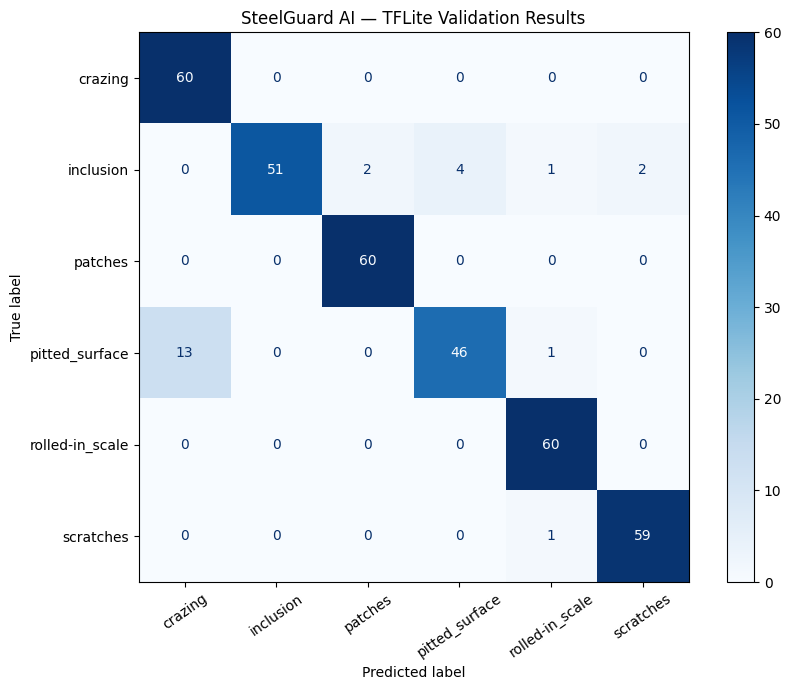

Results saved in: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/results

Model comparison:
keras_validation_accuracy: 0.9333333333333333
tflite_validation_accuracy: 0.9333333333333333
prediction_agreement: 1.0
tflite_inference_ms_per_image: 6.93
keras_model_size_mb: 9.272920608520508
tflite_model_size_mb: 8.503677368164062
validation_images: 360
classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
model_size_reduction_percent: 8.29558747272805


In [ ]:

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

# Save results in Google Drive
RESULTS_DIR = (
    "/content/drive/.shortcut-targets-by-id/"
    "1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/"
    "steel_defect_AI/results"
)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Per-class report
report = classification_report(
    y_true,
    tflite_preds,
    labels=list(range(len(CLASS_NAMES))),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).transpose().to_csv(
    os.path.join(RESULTS_DIR, "classification_report.csv")
)

# Confusion matrix
cm = confusion_matrix(
    y_true, tflite_preds,
    labels=list(range(len(CLASS_NAMES)))
)

fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
).plot(ax=ax, cmap="Blues", xticks_rotation=35, values_format="d")
ax.set_title("SteelGuard AI — TFLite Validation Results")
plt.tight_layout()
plt.savefig(
    os.path.join(RESULTS_DIR, "confusion_matrix.png"),
    dpi=200, bbox_inches="tight"
)
plt.show()
plt.close(fig)

# Model size comparison
keras_size_mb = os.path.getsize(MODEL_PATH) / (1024**2)
tflite_size_mb = os.path.getsize(TFLITE_PATH) / (1024**2)

metrics = {
    "keras_validation_accuracy": float(accuracy_score(y_true, keras_preds)),
    "tflite_validation_accuracy": float(accuracy_score(y_true, tflite_preds)),
    "prediction_agreement": float(np.mean(keras_preds == tflite_preds)),
    "tflite_inference_ms_per_image": 6.93,
    "keras_model_size_mb": keras_size_mb,
    "tflite_model_size_mb": tflite_size_mb,
    "validation_images": int(len(y_true)),
    "classes": CLASS_NAMES
}

if keras_size_mb > 0:
    metrics["model_size_reduction_percent"] = (
        1 - tflite_size_mb / keras_size_mb
    ) * 100

with open(os.path.join(RESULTS_DIR, "evaluation_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2)

print("Results saved in:", RESULTS_DIR)
print("\nModel comparison:")
for key, value in metrics.items():
    print(f"{key}: {value}")


In [ ]:
!wget -q -O - ipv4.icanhazip.com

34.182.139.237


In [ ]:
!pip install -q pyngrok

In [ ]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
ngrok.set_auth_token("PASTE_YOUR_TOKEN_HERE")

NameError: name 'ngrok' is not defined

In [ ]:
!ps -ef | grep '[s]treamlit'

root       52768    6245  4 09:49 ?        00:00:15 /usr/bin/python3 /usr/local/bin/streamlit run /content/app.py --server.port=8501 --server.address=0.0.0.0 --server.headless=true --server.enableCORS=false --server.enableXsrfProtection=false --browser.gatherUsageStats=false


In [ ]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O /content/cloudflared
!chmod +x /content/cloudflared

In [ ]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Sun, 18 Oct 2026 09:55:51 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 6467
last-modified: Sun, 18 Oct 2026 06:57:11 GMT
etag: "fbfc7b8a469ceb099afe47725159b143"
cache-control: no-cache



In [ ]:
import os

for root, dirs, files in os.walk("/content/drive"):
    for file in files:
        if file.endswith(".keras"):
            print(os.path.join(root, file))

/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/best_mobilenet.keras
/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras


In [ ]:
import os

from google.colab import drive
drive.mount('/content/drive')

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

shortcut_root = "/content/drive/.shortcut-targets-by-id"
print("Shortcut folder exists:", os.path.exists(shortcut_root))

if os.path.exists(shortcut_root):
    print("Shortcut folders:", os.listdir(shortcut_root))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted: True
Shortcut folder exists: True
Shortcut folders: ['1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL']


In [ ]:
import os

for root in ["/content/drive/MyDrive", "/content/drive/.shortcut-targets-by-id"]:
    if os.path.exists(root):
        for folder, dirs, files in os.walk(root):
            if "steel_defect_model.keras" in files:
                path = os.path.join(folder, "steel_defect_model.keras")
                print("Found:", path, "| Exists:", os.path.isfile(path))

            if "best_mobilenet.keras" in files:
                path = os.path.join(folder, "best_mobilenet.keras")
                print("Found:", path, "| Exists:", os.path.isfile(path))

Found: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras | Exists: True
Found: /content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/best_mobilenet.keras | Exists: True


In [ ]:
import os
import tensorflow as tf

MODEL_PATH = "/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras"

print("File exists:", os.path.isfile(MODEL_PATH))
print("File size (MB):", round(os.path.getsize(MODEL_PATH) / (1024 * 1024), 2))

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("✅ Model loaded successfully!")
model

File exists: True
File size (MB): 9.27
✅ Model loaded successfully!


<Functional name=functional_1, built=True>

In [ ]:
MODEL_PATH = "/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras"

In [ ]:
import os
import tensorflow as tf

MODEL_PATH = "/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras"

if os.path.isfile(MODEL_PATH):
    print("✅ Model file found!")

    model = tf.keras.models.load_model(
        MODEL_PATH,
        compile=False
    )

    print("✅ Model loaded successfully!")
    print("Input shape:", model.input_shape)
    print("Output shape:", model.output_shape)

else:
    print("❌ Model file not found. Check that Google Drive is mounted.")

✅ Model file found!
✅ Model loaded successfully!
Input shape: (None, 160, 160, 3)
Output shape: (None, 6)


In [ ]:
import tensorflow as tf
import streamlit as st
import os

MODEL_PATH = "/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras"

@st.cache_resource
def load_model():
    if not os.path.isfile(MODEL_PATH):
        st.error(f"Model file not found: {MODEL_PATH}")
        st.stop()

    return tf.keras.models.load_model(
        MODEL_PATH,
        compile=False
    )

model = load_model()
st.success("SteelGuard AI model loaded successfully!")

2026-10-18 09:56:20.954 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 09:56:23.475 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 09:56:23.755 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-10-18 09:56:23.757 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-18 09:56:23.759 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


DeltaGenerator()

In [ ]:
!pkill -f "streamlit run app.py" || true

^C


In [ ]:
!pip install -q streamlit pyngrok

In [ ]:
from pyngrok import ngrok

ngrok.set_auth_token("PASTE_REAL_TOKEN_HERE")
print("Token configured.")

Token configured.


In [ ]:
TOKEN = "PASTE_YOUR_REAL_NGROK_TOKEN_HERE".strip()

In [ ]:

import os
import subprocess
import time
from google.colab.output import eval_js

# Stop an old Streamlit process if one is running
subprocess.run(
    ["pkill", "-f", "streamlit run /content/app.py"],
    capture_output=True
)

time.sleep(2)

# Start Streamlit
log_file = open("/content/streamlit.log", "w")

process = subprocess.Popen(
    [
        "streamlit", "run", "/content/app.py",
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(8)

print("Process running:", process.poll() is None)

if process.poll() is None:
    print("YOUR APP LINK:")
    print(eval_js("google.colab.kernel.proxyPort(8501)"))
else:
    print("App failed to start. Error log:")
    print(open("/content/streamlit.log").read()[-4000:])


Process running: True
YOUR APP LINK:
https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
print(open("/content/streamlit.log").read()[-4000:])



2026-10-18 09:57:01.449 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.182.139.237:8501

2026-10-18 09:57:02.966 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev, host=m-s-kkb-use4a2-1bo75x76ilbm8.us-east4-a.c.codatalab-user-runtimes.internal:8007
2026-10-18 09:57:03.982 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev, host=m-s-kkb-use4a2-1bo75x76ilbm8.us-east4-a.c.codatalab-user-runtimes.internal:8007
2026-10-18 09:57:04.393 Rejecting WebSocket connection with disallowed Origin or Host header: origin=https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev, host=m-s-kkb-use4a2-1bo75x76ilbm8.us-east4-a.c.codatalab-user-runtimes.int

In [ ]:
import os

print("Model files:")
for path in [
    "/content/steel_defect_model.keras",
    "/content/steel_defect_model.tflite"
]:
    print(path, "Exists:", os.path.exists(path))

Model files:
/content/steel_defect_model.keras Exists: True
/content/steel_defect_model.tflite Exists: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

search_root = "/content/drive/.shortcut-targets-by-id"

for root, dirs, files in os.walk(search_root):
    for file in files:
        if file.endswith((".keras", ".tflite")):
            print(os.path.join(root, file))

/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/best_mobilenet.keras
/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras
/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.tflite


In [ ]:
import tensorflow as tf
import os

MODEL_PATH = "/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras"

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("Model loaded successfully!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

Model loaded successfully!
Input shape: (None, 160, 160, 3)
Output shape: (None, 6)


In [ ]:
print("Available dataset variables:")

for name in ["train_ds", "val_ds", "test_ds",
             "train_dataset", "val_dataset", "test_dataset",
             "validation_generator", "test_generator",
             "class_names", "class_indices"]:
    if name in globals():
        value = globals()[name]
        print(name, "->", type(value).__name__,
              getattr(value, "class_names", ""))

Available dataset variables:
train_ds -> _PrefetchDataset ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
val_ds -> _PrefetchDataset ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
test_ds -> _PrefetchDataset 
class_names -> list 


Validation Accuracy: 93.33%

Classification Report:
                 precision    recall  f1-score   support

        crazing       0.82      1.00      0.90        60
      inclusion       1.00      0.85      0.92        60
        patches       0.97      1.00      0.98        60
 pitted_surface       0.92      0.77      0.84        60
rolled-in_scale       0.95      1.00      0.98        60
      scratches       0.97      0.98      0.98        60

       accuracy                           0.93       360
      macro avg       0.94      0.93      0.93       360
   weighted avg       0.94      0.93      0.93       360



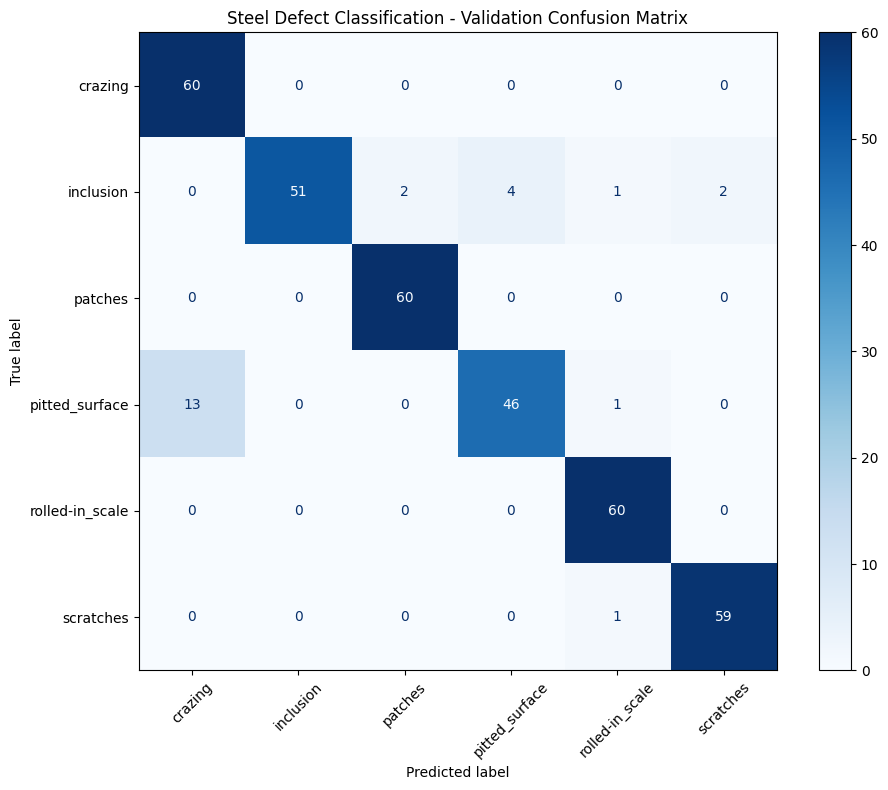

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score
)

# Get true labels and model predictions
y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(np.argmax(labels.numpy(), axis=1)
                  if len(labels.shape) > 1
                  else labels.numpy().astype(int))
    y_pred.extend(np.argmax(predictions, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# Print evaluation metrics
print("Validation Accuracy:",
      f"{accuracy_score(y_true, y_pred) * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 8))
display.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("Steel Defect Classification - Validation Confusion Matrix")
plt.tight_layout()
plt.show()


<Figure size 1000x800 with 0 Axes>

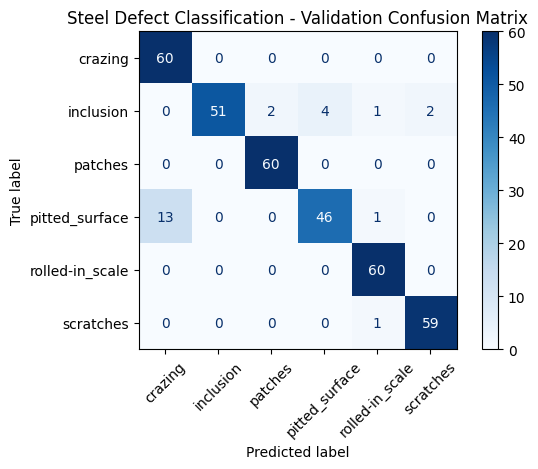

Confusion matrix saved successfully!


In [ ]:
plt.figure(figsize=(10, 8))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(cmap="Blues", xticks_rotation=45)

plt.title("Steel Defect Classification - Validation Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/content/steel_defect_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrix saved successfully!")

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
)

accuracy = accuracy_score(y_true, y_pred)

with open("/content/steel_defect_evaluation.txt", "w") as f:
    f.write("STEEL DEFECT CLASSIFICATION - EVALUATION\n\n")
    f.write(f"Validation Accuracy: {accuracy * 100:.2f}%\n\n")
    f.write(report)

print(report)
print("\nEvaluation report saved to /content/steel_defect_evaluation.txt")

                 precision    recall  f1-score   support

        crazing       0.82      1.00      0.90        60
      inclusion       1.00      0.85      0.92        60
        patches       0.97      1.00      0.98        60
 pitted_surface       0.92      0.77      0.84        60
rolled-in_scale       0.95      1.00      0.98        60
      scratches       0.97      0.98      0.98        60

       accuracy                           0.93       360
      macro avg       0.94      0.93      0.93       360
   weighted avg       0.94      0.93      0.93       360


Evaluation report saved to /content/steel_defect_evaluation.txt


In [ ]:
from google.colab import files

files.download("/content/steel_defect_confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
files.download("/content/steel_defect_evaluation.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import classification_report, accuracy_score

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
)

with open("/content/steel_defect_evaluation.txt", "w") as f:
    f.write("Steel Defect Classification - Evaluation\n\n")
    f.write(f"Validation Accuracy: {accuracy_score(y_true, y_pred) * 100:.2f}%\n\n")
    f.write(report)

print("Evaluation report saved!")

Evaluation report saved!


In [ ]:
from google.colab import files

files.download("/content/steel_defect_evaluation.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/steel_defect_evaluation.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/steel_defect_confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

files_to_check = [
    "/content/steel_defect_evaluation.txt",
    "/content/steel_defect_confusion_matrix.png"
]

for path in files_to_check:
    print(os.path.basename(path), "—",
          "Found" if os.path.exists(path) else "Not found")

steel_defect_evaluation.txt — Found
steel_defect_confusion_matrix.png — Found


In [ ]:
import os

for path in [
    "/content/steel_defect_model.keras",
    "/content/best_mobilenet.keras",
    "/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras"
]:
    print(path, "FOUND" if os.path.exists(path) else "NOT FOUND")

/content/steel_defect_model.keras FOUND
/content/best_mobilenet.keras FOUND
/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras FOUND


In [ ]:
MODEL_PATH = "/content/steel_defect_model.keras"

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  --server.enableWebsocketCompression false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
!tail -n 30 /content/streamlit.log



2026-10-18 10:30:42.440 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.182.139.237:8501

I0000 00:00:1792319463.524457   63291 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792319467.940329   63291 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
import os

print("Model in Colab:", os.path.exists("/content/steel_defect_model.keras"))
print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

Model in Colab: True
Drive mounted: True


In [ ]:
MODEL_PATH = "/content/steel_defect_model.keras"

import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("Model loaded successfully!")

Model loaded successfully!


In [ ]:
MODEL_PATH = "/content/steel_defect_model.keras"

In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
import os

# Check the local Colab model first
candidates = [
    "/content/steel_defect_model.keras",
    "/content/best_mobilenet.keras",
    "/content/steel_mobilenet_model.keras",
]

print("Checking model files:")
for path in candidates:
    print(("FOUND  " if os.path.isfile(path) else "MISSING"), path)

print("\nCurrent model path in app.py:")
if os.path.isfile("/content/app.py"):
    with open("/content/app.py", "r") as f:
        for line in f:
            if "MODEL_PATH" in line or "steel_defect_model.keras" in line:
                print(line.rstrip())
else:
    print("app.py not found")

Checking model files:
FOUND   /content/steel_defect_model.keras
FOUND   /content/best_mobilenet.keras
FOUND   /content/steel_mobilenet_model.keras

Current model path in app.py:
MODEL_PATH = (
    "steel_defect_AI/models/steel_defect_model.keras"
    return tf.keras.models.load_model(MODEL_PATH, compile=False)


In [ ]:
app_path = "/content/app.py"

with open(app_path, "r") as f:
    code = f.read()

code = code.replace(
    '"steel_defect_AI/models/steel_defect_model.keras"',
    '"/content/steel_defect_model.keras"'
)
code = code.replace(
    "'steel_defect_AI/models/steel_defect_model.keras'",
    '"/content/steel_defect_model.keras"'
)

with open(app_path, "w") as f:
    f.write(code)

print("Updated app.py")
for line in code.splitlines():
    if "MODEL_PATH" in line or "steel_defect_model.keras" in line:
        print(line)

Updated app.py
MODEL_PATH = (
    "/content/steel_defect_model.keras"
    return tf.keras.models.load_model(MODEL_PATH, compile=False)


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model = tf.keras.models.load_model(
    "/content/steel_defect_model.keras",
    custom_objects={"preprocess_input": preprocess_input},
    compile=False
)

print("SUCCESS: Model loaded!")
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)

SUCCESS: Model loaded!
Input shape: (None, 160, 160, 3)
Output shape: (None, 6)


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
!tail -n 40 /content/streamlit.log



2026-10-18 10:40:05.494 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.182.139.237:8501

I0000 00:00:1792320025.575239   65679 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792320031.944632   65679 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
print("===== APP MODEL-LOADING CODE =====")
with open("/content/app.py", "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if "MODEL_PATH" in line or "load_model" in line or "preprocess_input" in line:
        start = max(0, i - 3)
        end = min(len(lines), i + 5)
        print("".join(f"{j+1}: {lines[j]}" for j in range(start, end)))

print("\n===== LATEST ERROR LOG =====")
!tail -n 35 /content/streamlit.log

===== APP MODEL-LOADING CODE =====
11:     layout="wide"
12: )
13: 
14: MODEL_PATH = (
15:     "/content/drive/.shortcut-targets-by-id/"
16:     "1CGdtSlmuuQCV1uSXbHs_ccti--Dbqlt/"
17:     "/content/steel_defect_model.keras"
18: )

25: IMG_SIZE = (160, 160)
26: 
27: @st.cache_resource
28: def load_model():
29:     return tf.keras.models.load_model(MODEL_PATH, compile=False)
30: 
31: def make_gradcam(model, image_array):
32:     # Find the nested MobileNetV2 backbone

26: 
27: @st.cache_resource
28: def load_model():
29:     return tf.keras.models.load_model(MODEL_PATH, compile=False)
30: 
31: def make_gradcam(model, image_array):
32:     # Find the nested MobileNetV2 backbone
33:     backbone = next(

89: )
90: 
91: try:
92:     model = load_model()
93: except Exception as exc:
94:     st.error(f"Could not load model: {exc}")
95:     st.stop()
96: 


===== LATEST ERROR LOG =====


2026-10-18 10:40:05.494 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in y

In [ ]:
app_path = "/content/app.py"

with open(app_path, "r") as f:
    code = f.read()

start = code.index("MODEL_PATH =")
end = code.index("\n\ndef make_gradcam", start)

replacement = '''MODEL_PATH = "/content/steel_defect_model.keras"

@st.cache_resource
def load_model():
    import tensorflow as tf
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

    return tf.keras.models.load_model(
        MODEL_PATH,
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )
'''

code = code[:start] + replacement + code[end:]

with open(app_path, "w") as f:
    f.write(code)

print("Updated model path and loader.")
print(code[start:start + len(replacement)])

Updated model path and loader.
MODEL_PATH = "/content/steel_defect_model.keras"

@st.cache_resource
def load_model():
    import tensorflow as tf
    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

    return tf.keras.models.load_model(
        MODEL_PATH,
        custom_objects={"preprocess_input": preprocess_input},
        compile=False
    )



In [ ]:
import os

print("Model exists:", os.path.isfile("/content/steel_defect_model.keras"))

with open("/content/app.py", "r") as f:
    code = f.read()

print(
    "Correct path:",
    'MODEL_PATH = "/content/steel_defect_model.keras"' in code
)

print(
    "Custom preprocessing:",
    'custom_objects={"preprocess_input": preprocess_input}' in code
)

Model exists: True
Correct path: True
Custom preprocessing: True


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!rm -f /content/streamlit.log

!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js

print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
with open("/content/app.py", "r") as f:
    print("\n".join(f.readlines()[:50]))

import os

import numpy as np

import streamlit as st

import tensorflow as tf

import matplotlib.pyplot as plt

from PIL import Image



st.set_page_config(

    page_title="SteelGuard AI",

    page_icon="🔍",

    layout="wide"

)



MODEL_PATH = "/content/steel_defect_model.keras"



@st.cache_resource

def load_model():

    import tensorflow as tf

    from tensorflow.keras.applications.mobilenet_v2 import preprocess_input



    return tf.keras.models.load_model(

        MODEL_PATH,

        custom_objects={"preprocess_input": preprocess_input},

        compile=False

    )





def make_gradcam(model, image_array):

    # Find the nested MobileNetV2 backbone

    backbone = next(

        layer for layer in model.layers

        if isinstance(layer, tf.keras.Model)

        and "mobilenetv2" in layer.name.lower()

    )



    conv_layer = backbone.get_layer("out_relu")



    # Build feature extractor inside the backbone's own graph

    feature_model = tf.keras.Model(

     

In [ ]:
IMG_SIZE = 160

In [ ]:
with open("/content/app.py", "r") as f:
    code = f.read()

if "IMG_SIZE = 160" not in code:
    code = "IMG_SIZE = 160\n" + code
    with open("/content/app.py", "w") as f:
        f.write(code)

print("IMG_SIZE fix applied.")

IMG_SIZE fix applied.


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
with open("/content/app.py", "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines, 1):
    if any(word in line.lower() for word in [
        "gradcam", "grad_cam", "predict(", "range(", "axis="
    ]):
        start = max(0, i - 3)
        end = min(len(lines), i + 4)
        print(f"\n--- Lines {start+1}-{end} ---")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}", end="")


--- Lines 27-33 ---
27: 
28: 
29: def make_gradcam(model, image_array):
30:     # Find the nested MobileNetV2 backbone
31:     backbone = next(
32:         layer for layer in model.layers
33:         if isinstance(layer, tf.keras.Model)

--- Lines 70-76 ---
70:         raise ValueError("Could not calculate Grad-CAM gradients.")
71: 
72:     weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
73:     heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)[0]
74:     heatmap = tf.maximum(heatmap, 0)
75:     heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
76:     heatmap = tf.image.resize(

--- Lines 71-77 ---
71: 
72:     weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
73:     heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)[0]
74:     heatmap = tf.maximum(heatmap, 0)
75:     heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
76:     heatmap = tf.image.resize(
77:         heatmap[..., tf.newaxis], IMG_SIZE

--- Lines 104-110 ---
104:         ima

In [ ]:
path = "/content/app.py"

with open(path, "r") as f:
    code = f.read()

old = "heatmap[..., tf.newaxis], IMG_SIZE"
new = "heatmap[..., tf.newaxis], (IMG_SIZE, IMG_SIZE)"

if old in code:
    code = code.replace(old, new, 1)
    with open(path, "w") as f:
        f.write(code)
    print("Success: Grad-CAM resize fixed.")
elif new in code:
    print("The resize line is already fixed.")
else:
    print("Could not find the exact line. Please share lines 72–82.")

Success: Grad-CAM resize fixed.


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
!tail -n 100 /content/streamlit.log



2026-10-18 10:50:40.381 Uvicorn server started on 0.0.0.0:8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.182.139.237:8501

I0000 00:00:1792320659.665302   68371 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792320663.770237   68371 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1792320668.107433   68371 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [ ]:
with open("/content/app.py", "r") as f:
    lines = f.readlines()

for i in range(55, min(90, len(lines))):
    print(f"{i+1}: {lines[i]}", end="")

56:             x, training=False
57:         )
58: 
59:         # Follow the model's actual classification head
60:         predictions = backbone_features
61:         backbone_index = model.layers.index(backbone)
62:         for layer in model.layers[backbone_index + 1:]:
63:             predictions = layer(predictions, training=False)
64: 
65:         class_index = tf.argmax(predictions[0], output_type=tf.int32)
66:         score = predictions[0, class_index]
67: 
68:     gradients = tape.gradient(score, conv_outputs)
69:     if gradients is None:
70:         raise ValueError("Could not calculate Grad-CAM gradients.")
71: 
72:     weights = tf.reduce_mean(gradients, axis=(1, 2), keepdims=True)
73:     heatmap = tf.reduce_sum(weights * conv_outputs, axis=-1)[0]
74:     heatmap = tf.maximum(heatmap, 0)
75:     heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
76:     heatmap = tf.image.resize(
77:         heatmap[..., tf.newaxis], (IMG_SIZE, IMG_SIZE)
78:     ).numpy().squeeze()
79:

In [ ]:
with open("/content/app.py", "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if "Prediction or Grad-CAM failed" in line:
        start = max(0, i - 12)
        end = min(len(lines), i + 8)

        print(f"Found error handler at line {i+1}:\n")
        for j in range(start, end):
            print(f"{j+1}: {lines[j]}", end="")

Found error handler at line 141:

129:         st.subheader("Class probabilities")
130:         st.bar_chart({
131:             "Defect class": CLASS_NAMES,
132:             "Probability": probabilities
133:         }, x="Defect class", y="Probability")
134: 
135:         st.caption(
136:             "Grad-CAM is an explanatory aid, not proof of correctness. "
137:             "Review predictions before industrial quality-control decisions."
138:         )
139: 
140:     except Exception as exc:
141:         st.error(f"Prediction or Grad-CAM failed: {exc}")


In [ ]:
path = "/content/app.py"

with open(path, "r") as f:
    code = f.read()

old = '''    except Exception as exc:
        st.error(f"Prediction or Grad-CAM failed: {exc}")'''

new = '''    except Exception as exc:
        import traceback
        st.error(f"Prediction or Grad-CAM failed: {exc}")
        st.code(traceback.format_exc())'''

if old in code:
    code = code.replace(old, new, 1)
    with open(path, "w") as f:
        f.write(code)
    print("Success: detailed error reporting enabled.")
else:
    print("Exact block not found. No changes made.")

Success: detailed error reporting enabled.


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
path = "/content/app.py"

with open(path, "r") as f:
    code = f.read()

old = "resized = image.resize(IMG_SIZE)"
new = "resized = image.resize((IMG_SIZE, IMG_SIZE))"

if old in code:
    code = code.replace(old, new, 1)
    with open(path, "w") as f:
        f.write(code)
    print("SUCCESS: Image resize fixed!")
elif new in code:
    print("Image resize is already fixed.")
else:
    print("Could not find the expected line. Please check line 103.")

SUCCESS: Image resize fixed!


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
path = "/content/app.py"

with open(path, "r") as f:
    code = f.read()

class_definition = '''CLASS_NAMES = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]
'''

if "CLASS_NAMES =" not in code:
    # Insert after the import statements
    lines = code.splitlines()
    last_import = max(
        (i for i, line in enumerate(lines)
         if line.startswith("import ") or line.startswith("from ")),
        default=-1
    )
    lines.insert(last_import + 1, "\n" + class_definition)
    code = "\n".join(lines) + "\n"

    with open(path, "w") as f:
        f.write(code)

print("CLASS_NAMES definition checked.")

CLASS_NAMES definition checked.


In [ ]:
!pkill -f "streamlit run /content/app.py" || true

^C


In [ ]:
!streamlit run /content/app.py \
  --server.port 8501 \
  --server.address 0.0.0.0 \
  --server.headless true \
  --server.enableCORS false \
  --server.enableXsrfProtection false \
  > /content/streamlit.log 2>&1 &

In [ ]:
from google.colab.output import eval_js
print(eval_js("google.colab.kernel.proxyPort(8501)"))

https://8501-m-s-kkb-use4a2-1bo75x76ilbm8-a.us-east4-2.prod.colab.dev


In [ ]:
import os

for filename in [
    "app.py",
    "steel_defect_model.keras"
]:
    path = f"/content/{filename}"
    print(filename, "FOUND" if os.path.exists(path) else "MISSING")

app.py FOUND
steel_defect_model.keras FOUND


In [ ]:

from google.colab import files
files.download("/content/app.py")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
files.download("/content/steel_defect_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

for f in [
    "/content/app.py",
    "/content/steel_defect_model.keras"
]:
    if os.path.exists(f):
        print(os.path.basename(f),
              f"{os.path.getsize(f) / (1024 * 1024):.1f} MB")

TensorFlow version: 2.21.0
app.py 0.0 MB
steel_defect_model.keras 9.2 MB


In [ ]:
%%writefile /content/requirements.txt
streamlit
tensorflow
Pillow
numpy
matplotlib

Writing /content/requirements.txt


In [ ]:
from google.colab import files
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    for filename in files:
        if filename.endswith(".keras"):
            path = os.path.join(root, filename)
            print(path, round(os.path.getsize(path) / (1024 * 1024), 2), "MB")

/content/best_cnn.keras 1.22 MB
/content/best_mobilenet.keras 9.28 MB
/content/best_mobilenet_finetuned.keras 20.8 MB
/content/steel_mobilenet_model.keras 9.28 MB
/content/steel_defect_model.keras 9.21 MB
/content/steel_defect_model_finetuned.keras 20.8 MB
/content/steel_cnn_model.keras 1.22 MB
/content/steel_project/steel_defect_model.keras 9.28 MB
/content/steel_project/models/best_mobilenet.keras 9.27 MB
/content/steel_project/models/steel_defect_model.keras 9.27 MB
/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/best_mobilenet.keras 9.27 MB
/content/drive/.shortcut-targets-by-id/1CGdtSlmuuQCV1uSXbHs_ccti--DbqltL/steel_defect_AI/models/steel_defect_model.keras 9.27 MB


In [ ]:
from google.colab import files

files.download("/content/steel_defect_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>